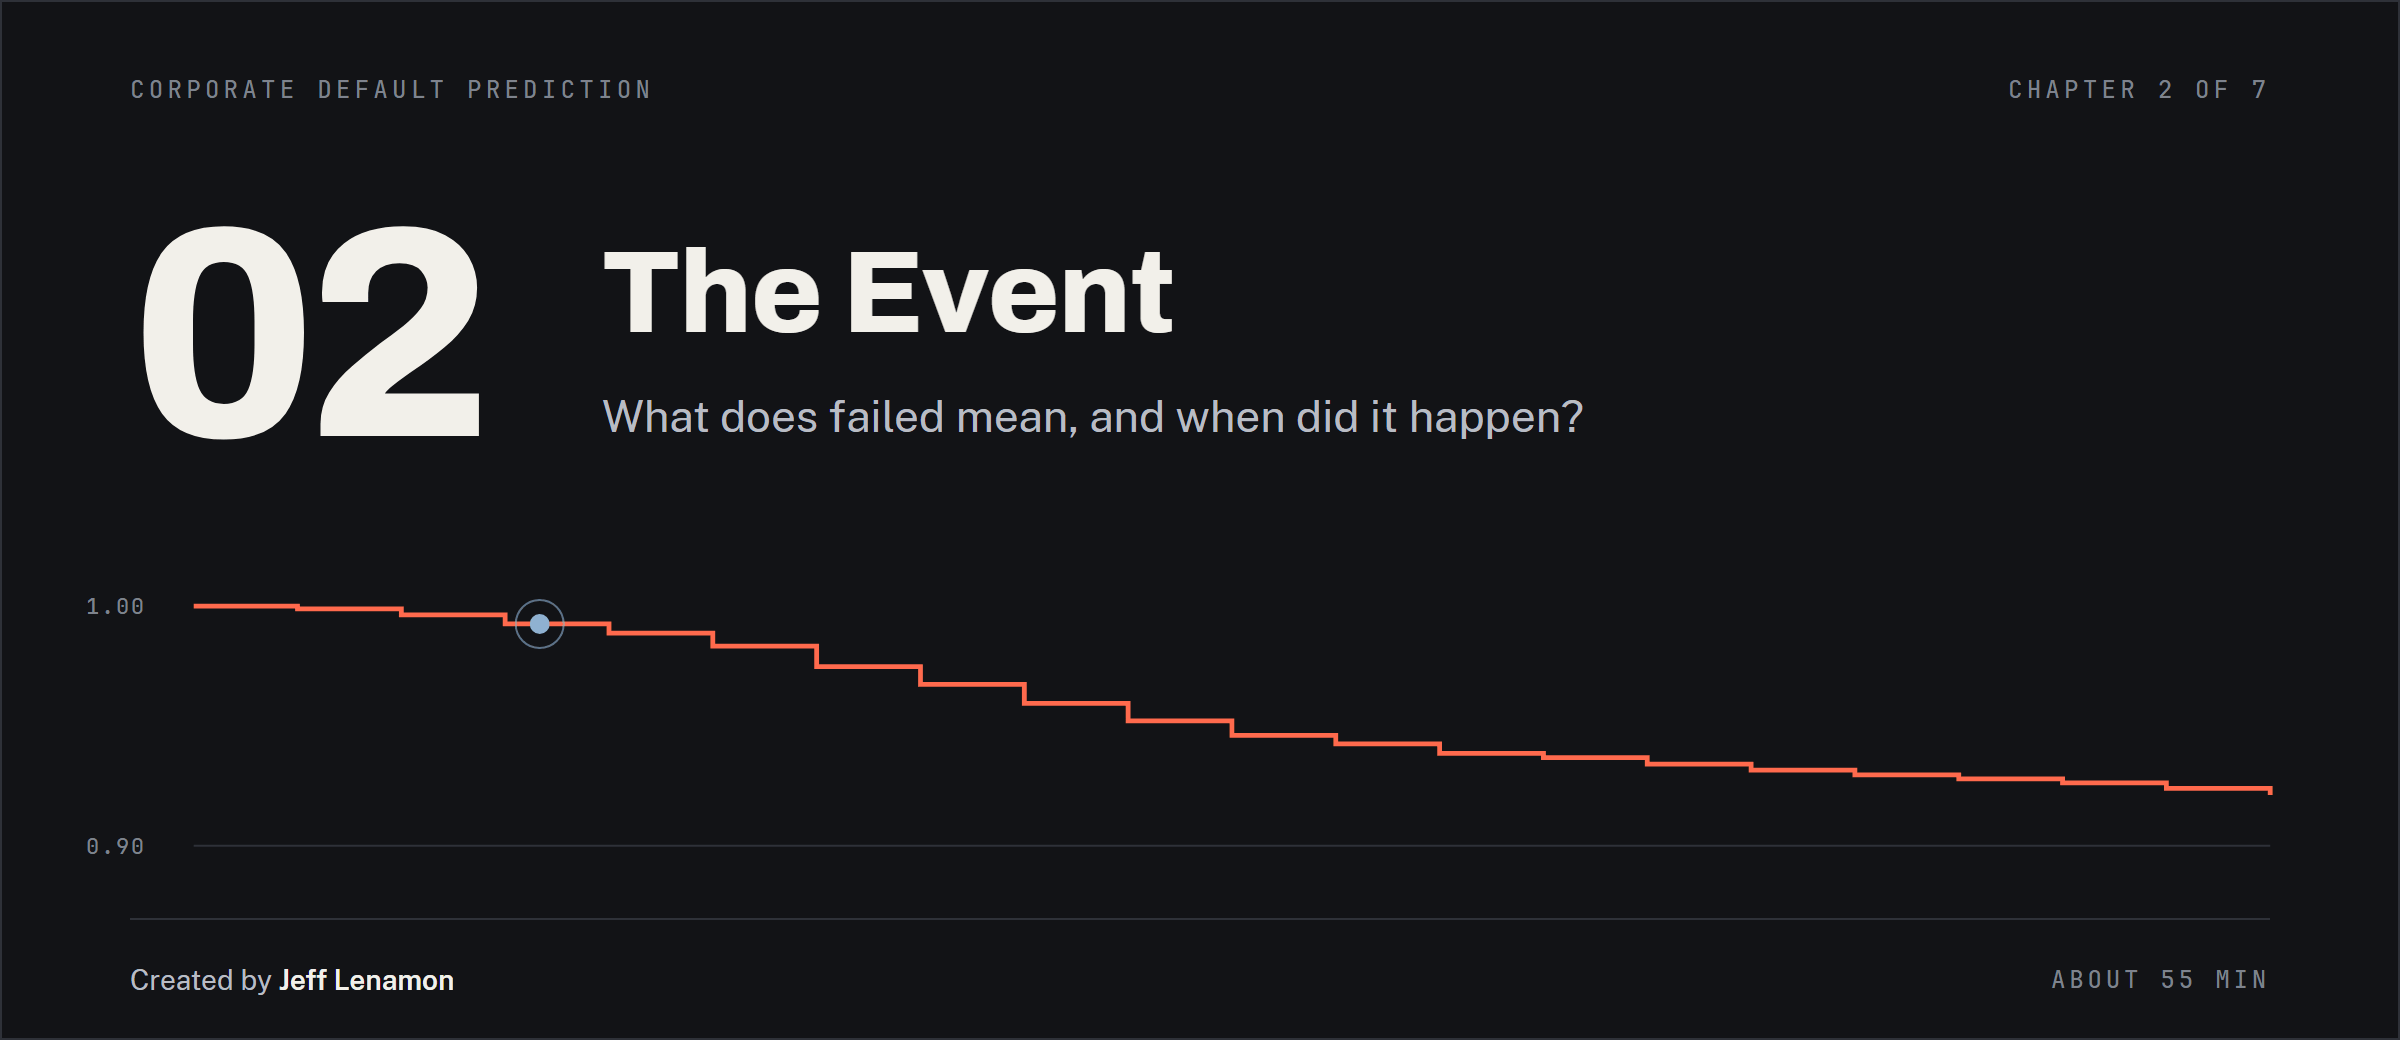

# Chapter 2: The Event

What it means for a company in this file to fail, when it happened, and what became of everyone else.

> This casebook is educational content created in a personal capacity

> Nothing here is investment advice or a recommendation to buy or sell any security

> The data is a public research dataset with anonymised company names

## The Question

The file marks 609 companies as `failed`.
It does not say when.

A model that predicts failure needs a date: this company, as of this year, fails soon.
What does failed mean here, and when did it happen?

## What You Will Learn

By the end you can:

- explain why the flag in the file cannot be used as a target;
- build a label that asks a dated question of each firm-year;
- check that label against the accounts of the companies it marks;
- account for the companies that leave without failing;
- draw survival curves that count every way out.

## What You Need

The data file, and Chapter 1 for what a panel, a firm-year, and the flag are.
This chapter reads nothing written by another one.

It writes two tables that every later chapter reads: the labelled panel and the event table.

## Your Route

![Your route through Chapter 2: 1 Setting Up, 5 minutes; 2 The Flag Is Not an Event, 6 minutes; 3 From a Flag to an Event Time, 4 minutes; 4 Is the Last Filing a Good Stand-In?, 4 minutes; 5 Failures Through Time, 3 minutes; 6 Everyone Else Who Leaves, 7 minutes; 7 Survival Curves Done Properly, 8 minutes; 8 The Horizon, 3 minutes; 9 The Label We Carry Forward, 1 minute.](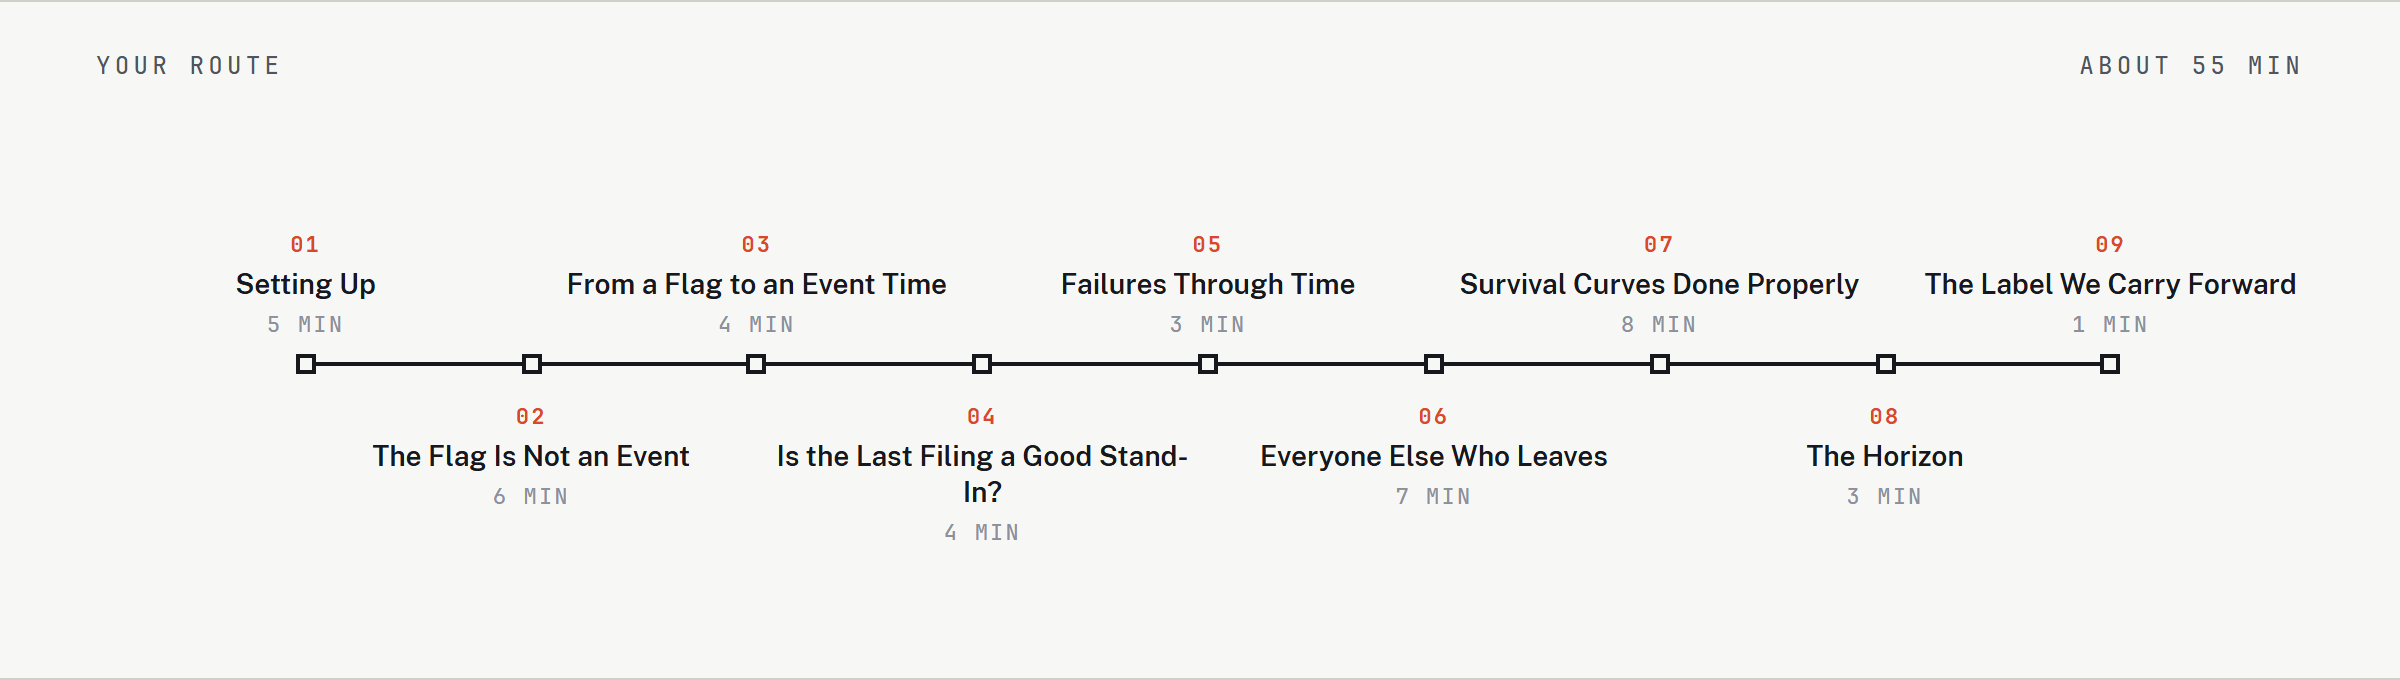)

**Time.** About 44 minutes to read and run, then about 9 for Your Turn.

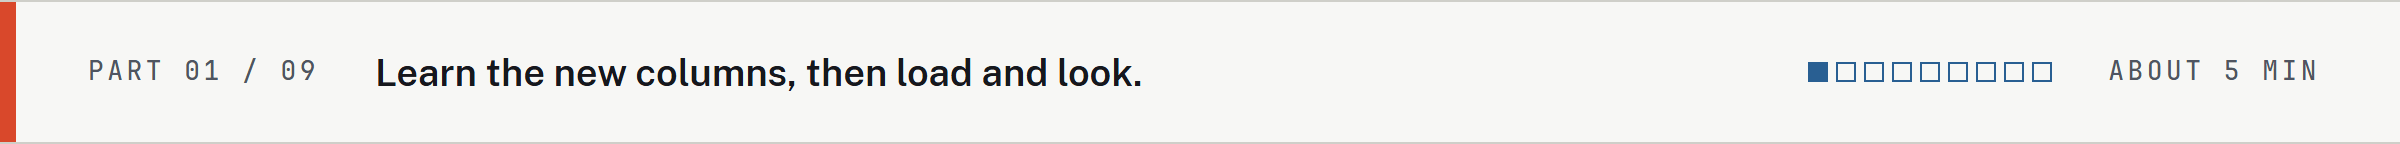

# Setting Up

Make sure the Jupyter kernel `corp-default` is selected before you run a cell.
If it is not in the list, or an import fails, the [Quick Start](../README.md#quick-start) shows how to register it and refresh the list.

## The Data Dictionary

The chapter starts from three columns of the file.

| Column | What it is |
| --- | --- |
| `company_name` | The company's code |
| `year` | The fiscal year of the accounts |
| `status_label` | `alive` or `failed`, the **flag** |

From them it builds a **label**: one answer for each firm-year.

| Column | What it is |
| --- | --- |
| `last_year` | The last fiscal year the company files |
| `failed` | True when the company carries the flag |
| `years_to_final` | Years from this row to the company's last filing |
| `target` | 1 when a flagged company's last filing comes one or two years after this row |
| `target_1`, `target_3` | The same question, asked one year ahead and three years ahead |

It also builds an **event table**: one row for each company.

| Column | What it is |
| --- | --- |
| `entry_year` | The first fiscal year the company files |
| `exit_year` | The last fiscal year the company files |
| `duration` | Years from the first to the last, counting both |
| `event` | How the history ends: `failed`, `left`, or `reporting` |

Two parts compare companies on four ratios, which Chapter 3 builds in full.

| Column | What it is |
| --- | --- |
| `roa` | Net income over total assets |
| `liabilities_to_assets` | Total liabilities over total assets |
| `working_capital_to_assets` | Current assets less current liabilities, over total assets |
| `log_assets` | The logarithm of total assets, a measure of size |

Q. What does the chapter need before it starts?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from corp_default import store, viz
from corp_default.classic import altman_z, altman_zone
from corp_default.data import RAW_ITEMS, load_raw
from corp_default.features import add_ratios
from corp_default.labels import PANEL_END
from corp_default.metrics import wilson_interval
from corp_default.splits import CRISIS_FINAL_YEARS, CRISIS_FOLDS, DEV_END, HORIZON

store.open_chapter(2)
viz.use_house_style()
SOURCE = "Lombardo et al. (2022), Kaggle copy"

raw = load_raw()

**Reading.** The panel is in memory, and the house style is set for every chart.
`store.put` carries a number from a cell into the text, so no number in this chapter is typed by hand.

Q. What does the table look like?

In [2]:
raw.head()

,company_name,status_label,year,current_assets,cogs,depreciation_amort,ebitda,inventory,net_income,total_receivables,market_cap,net_sales,total_assets,total_lt_debt,ebit,gross_profit,total_current_liabilities,retained_earnings,total_liabilities,total_operating_expenses
0,C_1,alive,1999,511.267,833.107,18.373,89.031,336.018,35.163,128.348,372.7519,1024.333,740.998,180.447,70.658,191.226,163.816,201.026,401.483,935.302
1,C_1,alive,2000,485.856,713.811,18.577,64.367,320.590,18.531,115.187,377.1180,874.255,701.854,179.987,45.790,160.444,125.392,204.065,361.642,809.888
2,C_1,alive,2001,436.656,526.477,22.496,27.207,286.588,-58.939,77.528,364.5928,638.721,710.199,217.699,4.711,112.244,150.464,139.603,399.964,611.514
3,C_1,alive,2002,396.412,496.747,27.172,30.745,259.954,-12.410,66.322,143.3295,606.337,686.621,164.658,3.573,109.590,203.575,124.106,391.633,575.592
4,C_1,alive,2003,432.204,523.302,26.680,47.491,247.245,3.504,104.661,308.9071,651.958,709.292,248.666,20.811,128.656,131.261,131.884,407.608,604.467


**Reading.** This is the table Chapter 1 took apart: one row for each company in each year.
The first three columns are this chapter's raw material.

Q. How large is the table, and what does each column hold?

In [3]:
first_year, last_year = int(raw["year"].min()), int(raw["year"].max())

store.put("firm_years", len(raw))
store.put("first_year", first_year)
store.put("last_year", last_year)
store.put("n_years", last_year - first_year + 1)
store.put("dev_end", DEV_END)

print(raw.shape)
raw.info()

(78682, 20)
<class 'pandas.DataFrame'>
RangeIndex: 78682 entries, 0 to 78681
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   company_name               78682 non-null  str    
 1   status_label               78682 non-null  str    
 2   year                       78682 non-null  int64  
 3   current_assets             78682 non-null  float64
 4   cogs                       78682 non-null  float64
 5   depreciation_amort         78682 non-null  float64
 6   ebitda                     78682 non-null  float64
 7   inventory                  78682 non-null  float64
 8   net_income                 78682 non-null  float64
 9   total_receivables          78682 non-null  float64
 10  market_cap                 78682 non-null  float64
 11  net_sales                  78682 non-null  float64
 12  total_assets               78682 non-null  float64
 13  total_lt_debt              78682 non-null  fl

**Reading.** The table has 78,682 rows, and no column is missing a value.
The company code and the flag are text, and the year is a whole number.

Q. What values do the three columns take?

In [4]:
KEYS = ["company_name", "status_label", "year"]

store.put("companies", raw["company_name"].nunique())
store.put("alive_rows", int((raw["status_label"] == "alive").sum()))

raw[KEYS].describe(include="all").T.fillna("")

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
company_name,78682,8971,C_7,20,,,,,,,
status_label,78682,2,alive,73462,,,,,,,
year,78682.0,,,,2007.506317,5.742768,1999.0,2002.0,2007.0,2012.0,2018.0


**Reading.** There are 8,971 company codes, and the years run from 1999 to 2018.
The flag takes two values, and `alive` is on 73,462 of the rows.

**Next, why the flag cannot be used as it stands.**

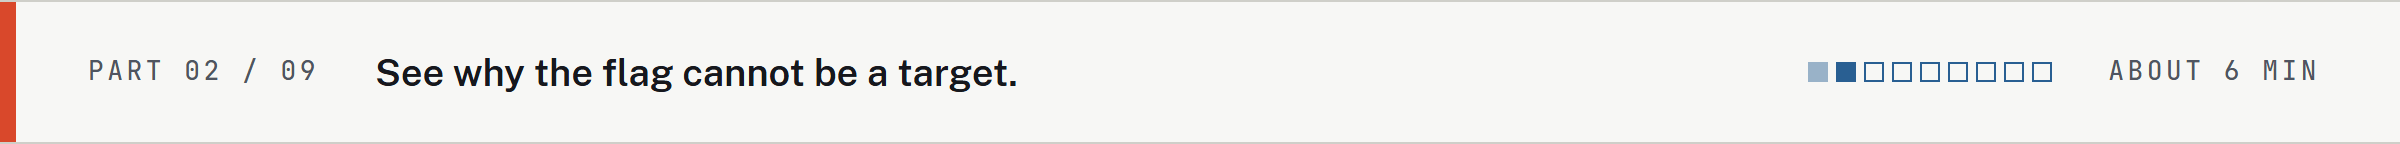

# The Flag Is Not an Event

The quickest way to a target is to use the flag as it is: `failed` is 1 and `alive` is 0.
Two things go wrong, and both are easy to miss.

Q. How many rows of a failed company carry the flag?

In [5]:
flagged = raw["status_label"] == "failed"
labels_per_company = raw.groupby("company_name")["status_label"].nunique()
rows_per_failed = raw.loc[flagged].groupby("company_name").size()

store.put("failed_companies", len(rows_per_failed))
store.put("failed_rows", int(flagged.sum()))
store.put("most_failed_rows", rows_per_failed.max())

print("most labels any one company carries:", labels_per_company.max())
rows_per_failed.describe().loc[["min", "50%", "max"]].astype(int).to_frame("flagged rows")

most labels any one company carries: 1


,flagged rows
min,1
50%,8
max,20


**Reading.** No company changes its label, so a failed company is flagged on every row it has.
The 609 failed companies carry the flag on 5,220 rows, as many as 20 for one company.

A flagged row from 1999 can describe a bankruptcy many years later.

**Predict 1.** Take the share of rows flagged `failed` in each year and call it a default rate.
How does it move from 1999 to 2018?

Q. What share of each year's rows carry the flag?

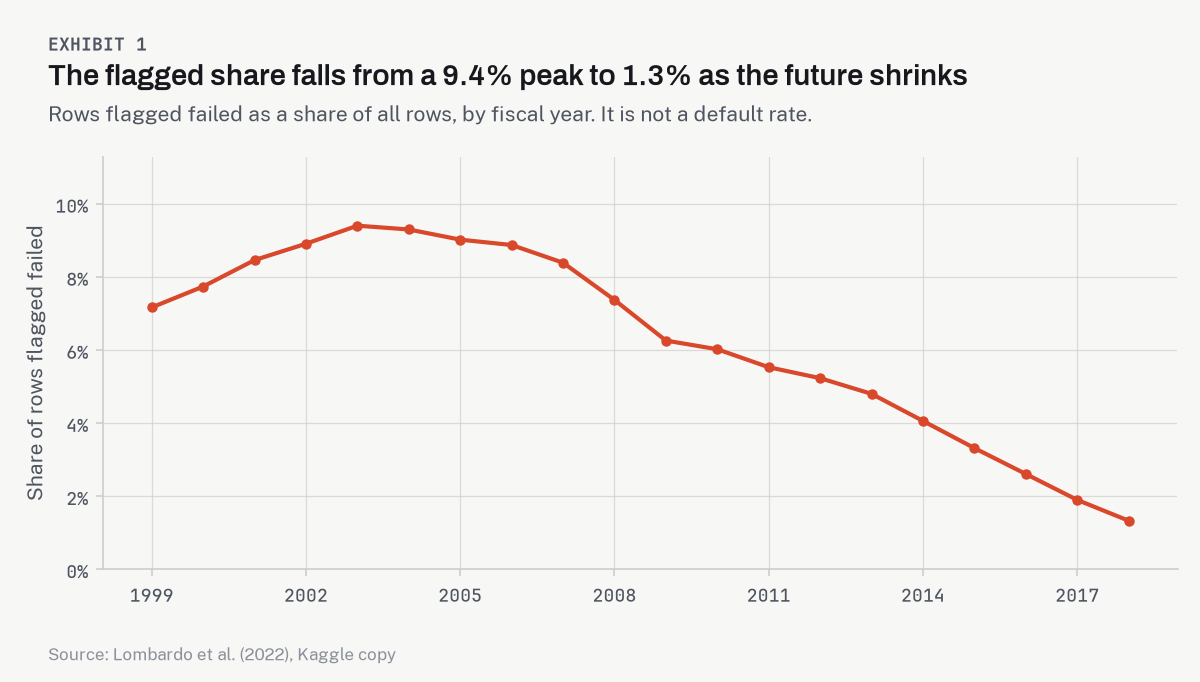

In [6]:
flag_rate = flagged.groupby(raw["year"]).mean()

store.put("flag_first", flag_rate.loc[first_year])
store.put("flag_peak", flag_rate.max())
store.put("flag_last", flag_rate.loc[last_year])

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.2))
ax.plot(flag_rate.index, flag_rate, color=viz.FAILED, marker="o", markersize=4)
ax.set_xticks(range(first_year, last_year + 1, 3))
ax.set_ylim(0, flag_rate.max() * 1.2)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylabel("Share of rows flagged failed")
viz.exhibit(
    fig,
    f"The flagged share falls from a {flag_rate.max():.1%} peak to {flag_rate.loc[last_year]:.1%} "
    "as the future shrinks",
    "Rows flagged failed as a share of all rows, by fiscal year. It is not a default rate.",
    SOURCE,
)

**Reading.** Exhibit 1 reads like credit quality improving for 20 years, from 7.2% to 1.3%.
It shows nothing of the kind.

The 1999 point counts every company that fails at any time before the file ends.
The 2018 point counts only the companies about to fail.
The line falls because the future gets shorter.

It rises to 9.4% first because unflagged companies are already leaving while few flagged ones have failed yet.

The second problem shows when a model of the flag is tested.
A random split puts rows of one company on both sides, and every one of them carries the same flag.

The test below uses fiscal years up to 2011 only, as every model fit before Chapter 7 does.
It fits a logistic regression and gradient-boosted trees to the raw accounts, and scores each on rows held out at random and on companies held out whole.

The score is the **ROC-AUC**: the chance that the model ranks a flagged row above an unflagged one.
A coin scores a half, and Chapter 4 treats the measure properly.

Q. How well does a model of the flag score, and does the split matter?

In [7]:
dev = raw.loc[raw["year"] <= DEV_END]
accounts = dev[RAW_ITEMS]
flag = (dev["status_label"] == "failed").astype(int)

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Gradient-boosted trees": HistGradientBoostingClassifier(random_state=42),
}
held_out = {
    "Rows at random": (KFold(5, shuffle=True, random_state=42), None),
    "Whole companies": (GroupKFold(5), dev["company_name"]),
}


def out_of_fold_auc(model, cv, groups) -> float:
    """ROC-AUC of predictions made for each row by a model that was not fitted on it."""
    scores = cross_val_predict(model, accounts, flag, cv=cv, groups=groups, method="predict_proba")
    return roc_auc_score(flag, scores[:, 1])


auc = pd.DataFrame(
    {
        name: {
            split: out_of_fold_auc(model, cv, groups) for split, (cv, groups) in held_out.items()
        }
        for name, model in models.items()
    }
).T

store.put("flag_auc_rows", auc.loc["Gradient-boosted trees", "Rows at random"])
store.put("flag_auc_companies", auc.loc["Gradient-boosted trees", "Whole companies"])
store.put("logit_auc_rows", auc.loc["Logistic regression", "Rows at random"])
store.put("logit_auc_companies", auc.loc["Logistic regression", "Whole companies"])

auc.round(3)

,Rows at random,Whole companies
Logistic regression,0.644,0.625
Gradient-boosted trees,0.797,0.675


**Reading.** On rows held out at random the trees score 0.797.
With whole companies held out, the same trees score 0.675.

The gap is the model recognising companies it has already met.
The logistic regression is too stiff to recognise a company, so its two scores sit close together, at 0.644 and 0.625.

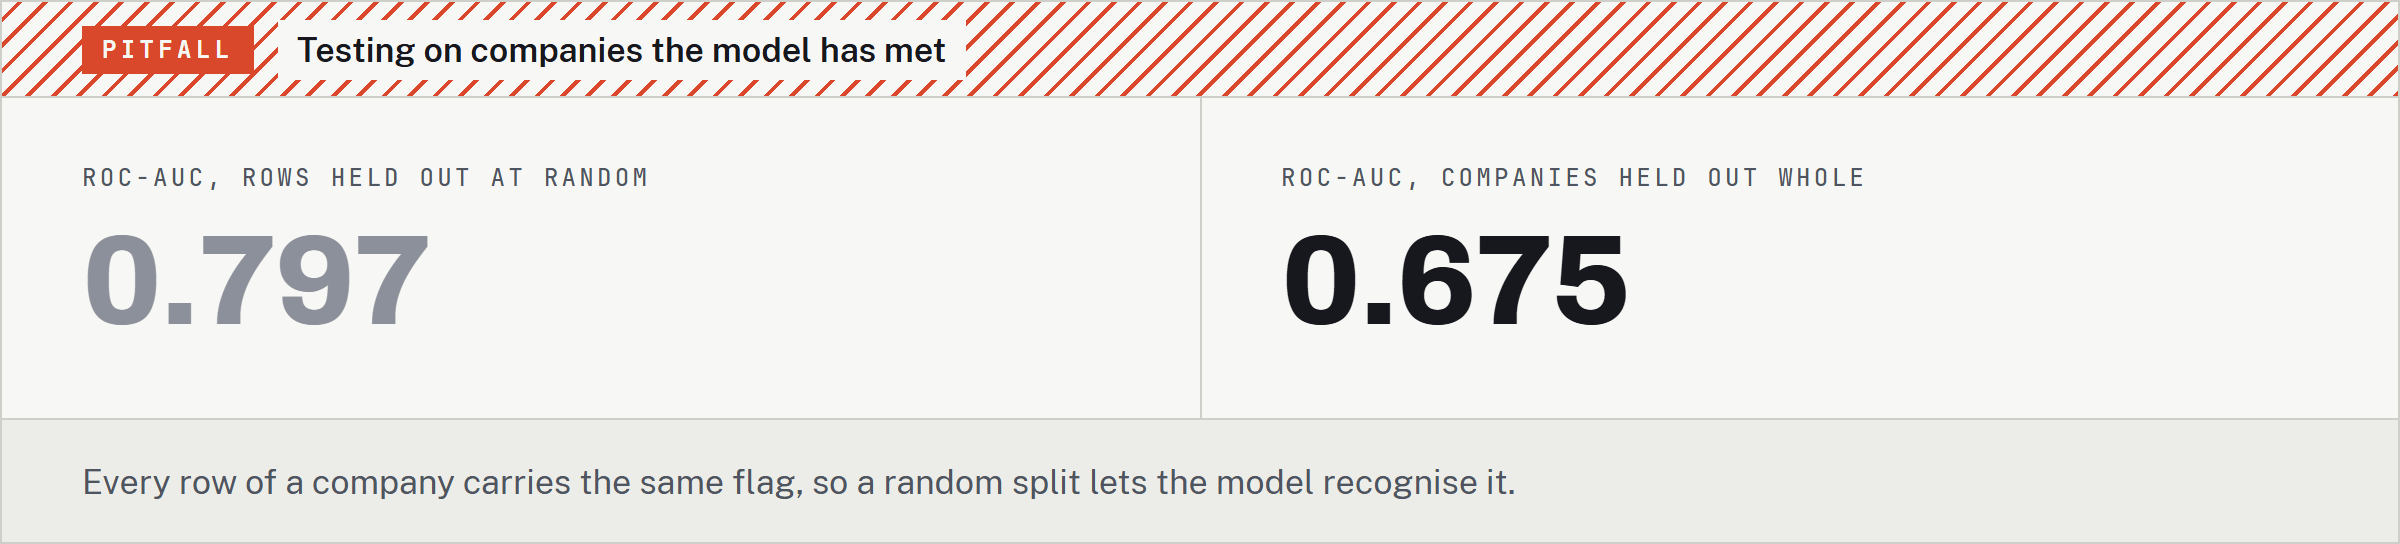

**Check.** Suppose the split by company had scored as high as the split by rows. Would the flag then be a good target?

<details>
<summary>Show the answer</summary>

No.
It would still have no date.

A flagged row says the company fails at some point before the file ends, which may be next year or many years away.
A lender needs to know about the next year or two.

</details>

**Next, a date for the failure.**

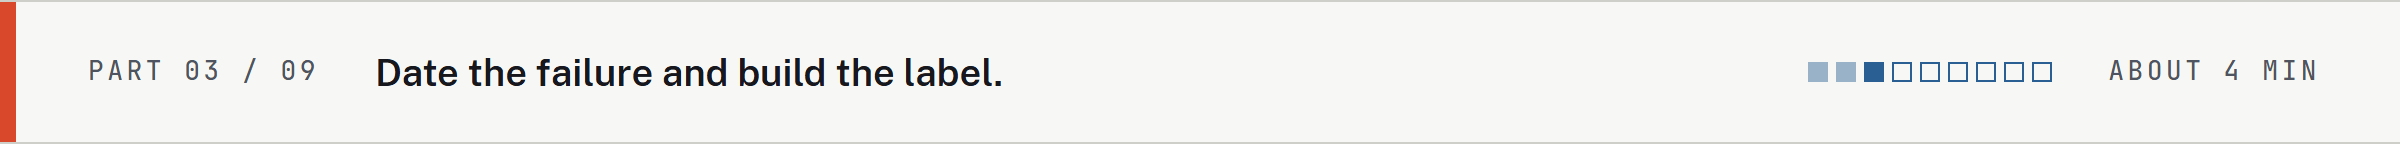

# From a Flag to an Event Time

The flag has no date, so the date has to come from the filings.
A company that goes bankrupt stops filing accounts.

[The paper](https://doi.org/10.3390/fi14080244) says where it put its label: on the fiscal year before the bankruptcy filing.
If the file follows that rule, a failed company's last year in the file is the year before it filed.

Q. Does the file agree with the paper's own count of failures by year?

In [8]:
PAPER_FAILURES = {2000: 3, 2001: 7, 2002: 10, 2003: 17}  # the paper's Table 1; see SOURCES.md
PAPER_TOTAL = 609

last_year_of = raw.groupby("company_name")["year"].max()
is_last = raw["year"] == raw["company_name"].map(last_year_of)
final_filings = raw.loc[flagged & is_last, "year"].value_counts().sort_index()

compare = pd.DataFrame(
    {
        "last year in the file": [year - 1 for year in PAPER_FAILURES],
        "failed companies, file": [final_filings.loc[year - 1] for year in PAPER_FAILURES],
        "year in the paper": list(PAPER_FAILURES),
        "failures, paper": list(PAPER_FAILURES.values()),
    }
)
# The reading below says the two counts agree. Checked here.
assert (compare["failed companies, file"] == compare["failures, paper"]).all()
assert final_filings.sum() == PAPER_TOTAL

store.put("early_failed", int(compare["failed companies, file"].sum()))
thin_until = max(PAPER_FAILURES) - 1  # the last of the early years the table covers
store.put("thin_until", thin_until)

compare

,last year in the file,"failed companies, file",year in the paper,"failures, paper"
0,1999,3,2000,3
1,2000,7,2001,7
2,2001,10,2002,10
3,2002,17,2003,17


**Reading.** The counts agree once the paper's year is read as the file's year plus one.
`SOURCES.md` records that they agree in all 20 years.

So a failed company's last row is its last fiscal year before the bankruptcy filing.
That makes the **last filing** a dated stand-in for the event.

The label asks one question of each firm-year.
Standing in year `t` with that year's accounts, is this company's last filing one or two years away?

This is a **hazard label**: the question is asked again every year the company files, and the answer is no until the end is near.

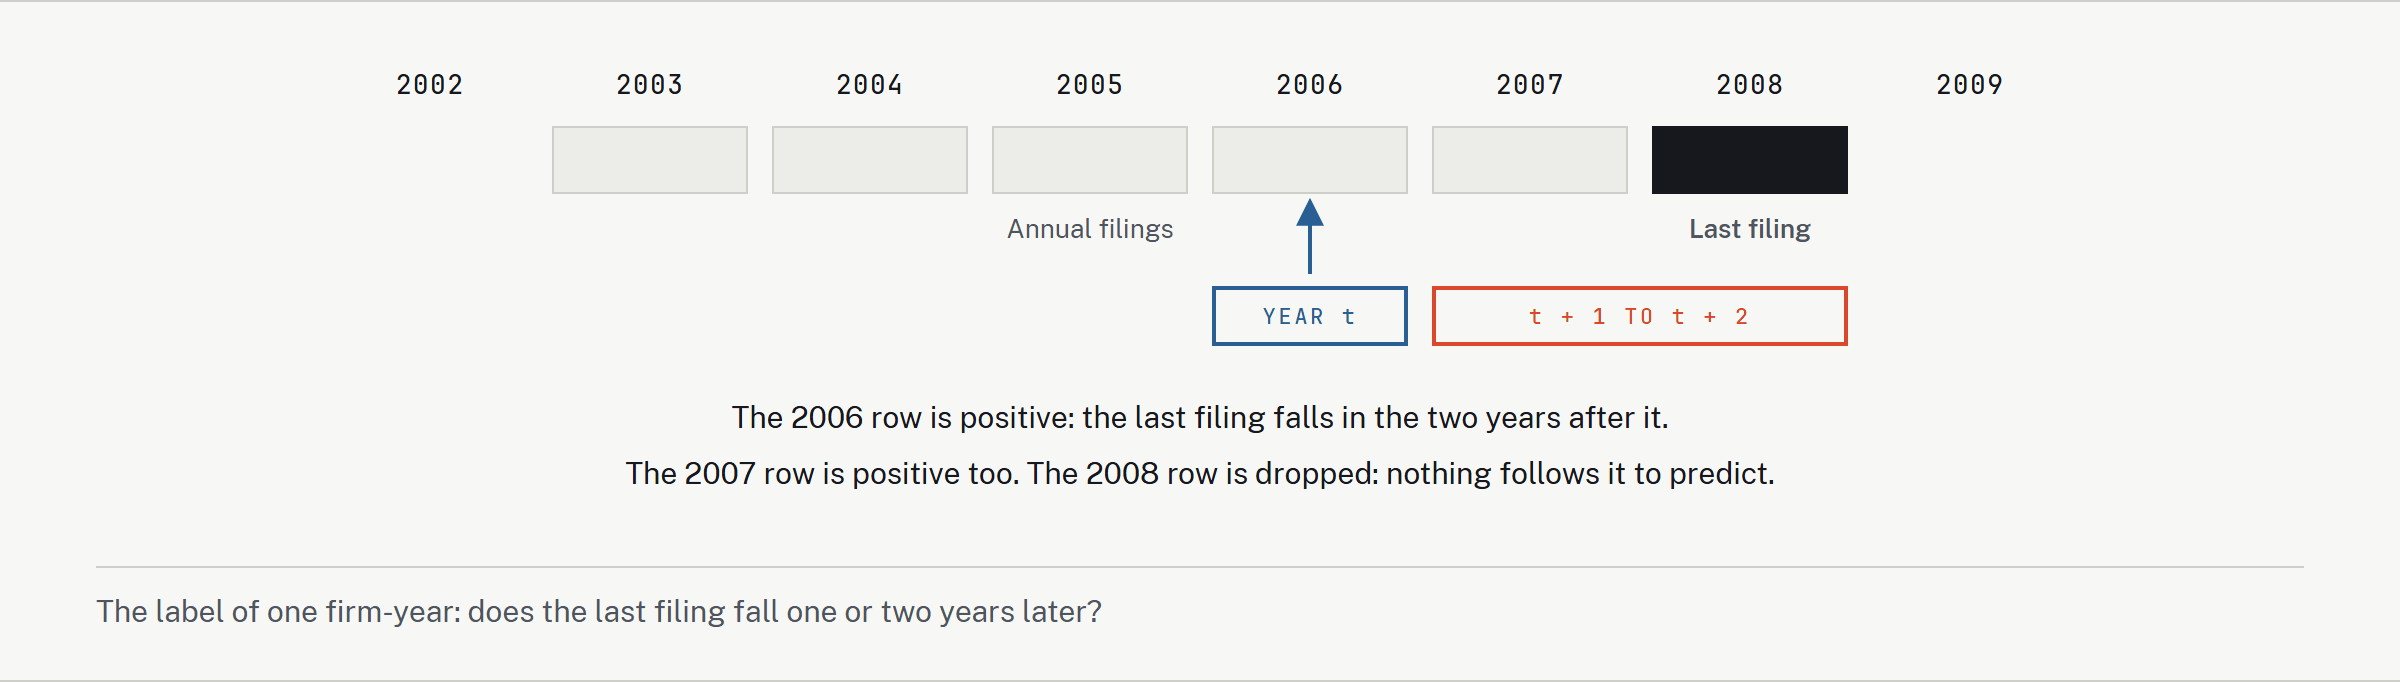

Two kinds of row cannot be asked the question, and the function drops them:

- the last row of a failed company, because that row is the event and nothing follows it to predict;
- a row whose two-year window runs past the end of the file, because its answer is not known yet.

Q. How does the library build the label?

In [9]:
# taught: corp_default.labels.build_label
def build_label(frame: pd.DataFrame, horizon: int) -> pd.DataFrame:
    """Label each firm-year: does the company's last filing fall 1 to `horizon` years later?

    Drops the final-year rows of failed companies, which have no future to predict, and every
    row whose outcome window runs past PANEL_END, where the outcome is not yet known.
    """
    last_year = frame.groupby("company_name")["year"].max().rename("last_year")
    frame = frame.join(last_year, on="company_name")
    frame = frame.assign(
        failed=frame["status_label"] == "failed",
        years_to_final=frame["last_year"] - frame["year"],
    )
    terminal = frame["failed"] & (frame["years_to_final"] == 0)
    frame = frame.loc[~terminal & (frame["year"] + horizon <= PANEL_END)]
    in_window = frame["failed"] & frame["years_to_final"].between(1, horizon)
    return frame.assign(target=in_window.astype(int))

Q. How many rows does the label keep, and how many are positive?

In [10]:
labelled = build_label(raw, HORIZON)
past_window = ~(flagged & is_last) & (raw["year"] + HORIZON > PANEL_END)

store.put("labelled_rows", len(labelled))
store.put("positives", int(labelled["target"].sum()))
store.put("base_rate", labelled["target"].mean())
store.put("last_labelled_year", int(labelled["year"].max()))

pd.Series(
    {
        "rows in the file": len(raw),
        "last rows of failed companies, dropped": int((flagged & is_last).sum()),
        f"rows after {PANEL_END - HORIZON}, dropped": int(past_window.sum()),
        "rows kept": len(labelled),
        "positive rows": int(labelled["target"].sum()),
    },
    name="rows",
).to_frame()

,rows
rows in the file,78682
"last rows of failed companies, dropped",609
"rows after 2016, dropped",5680
rows kept,72393
positive rows,1123


**Reading.** The label keeps 72,393 of the 78,682 rows, and the last year it can label is 2016.
Of the rows kept, 1,123 are positive.

That is a **base rate** of 1.55%.
A failed company gives at most two positive rows, the two before its last.

Q. Is the label built the way the text says?

The checks below run every time the notebook runs, and the chapter stops if one fails.

In [11]:
positive = labelled["target"] == 1

# The count first: the last two checks look only at positive rows, and would pass on none.
assert labelled["target"].sum() == 1123, "the count of positive rows has moved"
assert not (labelled["failed"] & (labelled["years_to_final"] == 0)).any(), (
    "the last row of a failed company was kept"
)
assert labelled["year"].max() == PANEL_END - HORIZON, "a window runs past the end of the file"
assert labelled.loc[positive, "failed"].all(), "a positive row belongs to a company not flagged"
assert labelled.loc[positive, "years_to_final"].between(1, HORIZON).all(), (
    "a positive row lies outside the window"
)
print("label checks passed")

label checks passed


**Reading.** Every check passes.
The columns `failed`, `last_year`, and `years_to_final` describe the outcome, so they are for checks like these and never for a model.

**Next, whether a last filing looks like a company about to fail.**

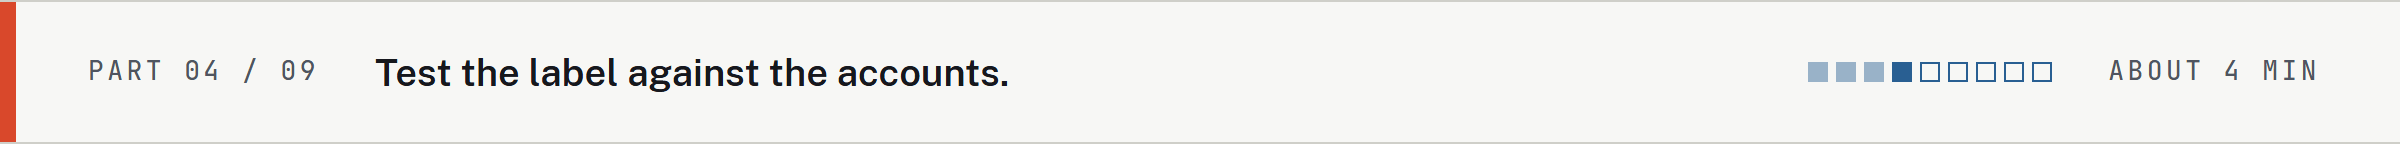

# Is the Last Filing a Good Stand-In?

The label rests on one assumption: a flagged company's last filing marks its failure.
The file cannot confirm that, but it can show whether those last filings look like companies in trouble.

The yardstick is one a credit analyst knows: the Z-score of [Altman (1968)](https://doi.org/10.1111/j.1540-6261.1968.tb00843.x).
It combines five ratios and sorts a company into a distress zone, a grey zone, or a safe zone.

It was built for manufacturers, and it serves here as an outside opinion only.
Chapter 4 takes it apart.

The check uses the failed companies whose last filing is 2011 or earlier.
It compares them with every other firm-year up to 2011, and later years stay out of sight until Chapter 7.

Q. Which zone is a failed company in at its last filing?

In [12]:
ratios = add_ratios(raw)
ratios = ratios.assign(zone=altman_zone(altman_z(ratios)))
to_dev_end = ratios["year"] <= DEV_END

audit = ratios.loc[flagged & is_last & to_dev_end]
others = ratios.loc[to_dev_end & ~(flagged & is_last)]
zones = pd.DataFrame(
    {
        "failed, last filing": audit["zone"].value_counts(normalize=True),
        "every other firm-year": others["zone"].value_counts(normalize=True),
    }
).loc[["distress", "grey", "safe"]]

store.put("audit_companies", len(audit))
store.put("audit_distress", zones.loc["distress", "failed, last filing"])
store.put("audit_safe", zones.loc["safe", "failed, last filing"])
store.put("audit_safe_companies", int((audit["zone"] == "safe").sum()))
store.put("others_distress", zones.loc["distress", "every other firm-year"])

zones.round(3)

,"failed, last filing",every other firm-year
zone,,
distress,0.754,0.352
grey,0.122,0.173
safe,0.124,0.475


**Reading.** Of the 403 failed companies, 75.4% are in the distress zone at their last filing.
Among all the other firm-years the share is 35.2%.

The safe zone still holds 12.4% of them, which is 50 companies.

Q. Where do those last filings sit on leverage and profitability?

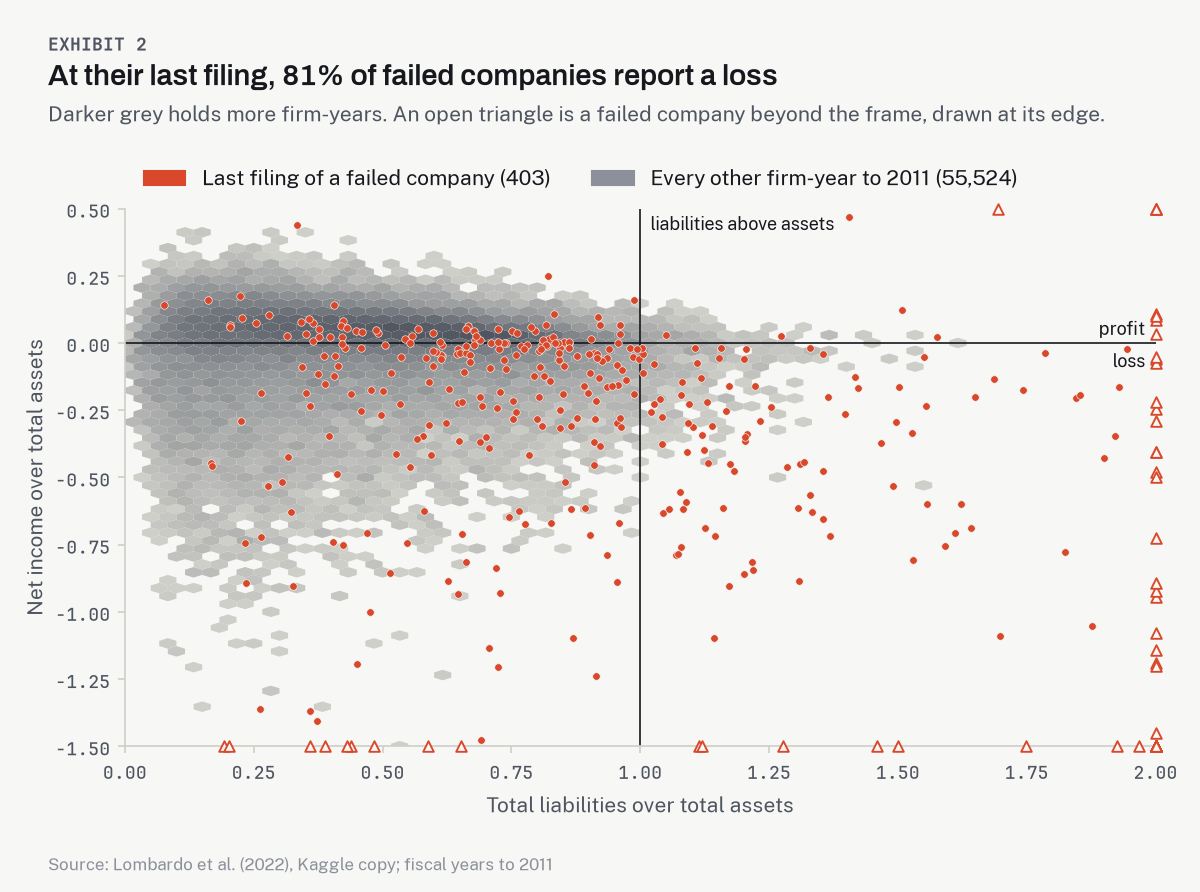

In [13]:
FRAME = {"liabilities_to_assets": (0, 2), "roa": (-1.5, 0.5)}


def framed(frame: pd.DataFrame) -> list[pd.Series]:
    """The two ratios, with values beyond the frame moved to its edge."""
    return [frame[column].clip(*limits) for column, limits in FRAME.items()]


loss_share = (audit["net_income"] < 0).mean()
store.put("audit_loss", loss_share)
store.put("audit_negative_equity", (audit["liabilities_to_assets"] > 1).mean())
store.put("others_loss", (others["net_income"] < 0).mean())

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 4.6))
cloud = LinearSegmentedColormap.from_list("cloud", [viz.RULE, viz.SLATE])
# The cloud is drawn where it is dense: a cell needs five firm-years to show.
ax.hexbin(
    others["liabilities_to_assets"],
    others["roa"],
    gridsize=60,
    extent=(*FRAME["liabilities_to_assets"], *FRAME["roa"]),
    bins="log",
    mincnt=5,
    cmap=cloud,
    linewidths=0,
)
leverage, returns = framed(audit)
beyond = (leverage != audit["liabilities_to_assets"]) | (returns != audit["roa"])
ax.scatter(leverage[~beyond], returns[~beyond], s=13, color=viz.FAILED, edgecolor=viz.SHEET,
           linewidth=0.3, zorder=3)  # fmt: skip
ax.scatter(leverage[beyond], returns[beyond], s=26, marker="^", facecolor=viz.SHEET,
           edgecolor=viz.FAILED, linewidth=0.9, zorder=3, clip_on=False)  # fmt: skip
ax.axhline(0, color=viz.INK, linewidth=0.8)
ax.axvline(1, color=viz.INK, linewidth=0.8)
ax.text(1.02, 0.42, "liabilities above assets", size=8.5, color=viz.INK)
ax.text(1.98, 0.03, "profit", size=8.5, color=viz.INK, ha="right")
ax.text(1.98, -0.09, "loss", size=8.5, color=viz.INK, ha="right")
ax.set_xlim(*FRAME["liabilities_to_assets"])
ax.set_ylim(*FRAME["roa"])
ax.grid(visible=False)
ax.set_xlabel("Total liabilities over total assets")
ax.set_ylabel("Net income over total assets")
ax.legend(
    handles=[
        Patch(color=viz.FAILED, label=f"Last filing of a failed company ({len(audit)})"),
        Patch(color=viz.MIST, label=f"Every other firm-year to {DEV_END} ({len(others):,})"),
    ],
    loc="lower left",
    bbox_to_anchor=(0, 1.0),
    ncols=2,
)
viz.exhibit(
    fig,
    f"At their last filing, {loss_share:.0%} of failed companies report a loss",
    "Darker grey holds more firm-years. An open triangle is a failed company beyond the frame, "
    "drawn at its edge.",
    f"{SOURCE}; fiscal years to {DEV_END}",
)

**Reading.** The red points in Exhibit 2 sit low and to the right of the grey cloud: losses, and liabilities close to or above assets.
A loss shows in 81% of the last filings, against 43% of the other firm-years.

Liabilities are above assets in 39% of them.
So the last filing mostly looks like what it is taken to be, the accounts of a company near the end.

The red points inside the healthy part of the cloud are the exceptions.

**Check.** A failed company's last accounts look healthy. Give two ways that can happen.

<details>
<summary>Show the answer</summary>

The failure may have little to do with the accounts: a lawsuit, a fraud, or a debt that could not be refinanced.

Or the last filing may be stale.
A company that stops filing well before it goes bankrupt gets an event date that is too early.

The file cannot tell the two apart.

</details>

**Next, the label through time.**

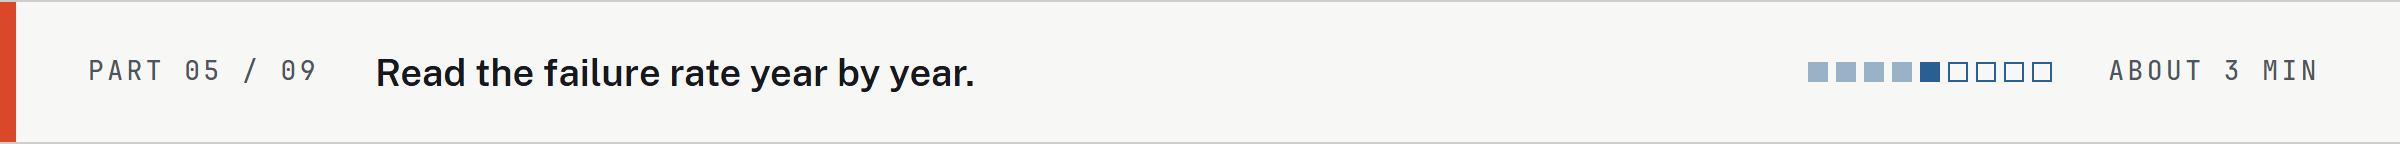

# Failures Through Time

With a date on each failure, a rate by year means something.
It is the share of the companies filing in a year whose last filing comes within two years.

A recession should show in it.
The [National Bureau of Economic Research](https://www.nber.org/research/data/us-business-cycle-expansions-and-contractions) dates two in these years: the 2001 recession, and the 2007 to 2009 recession.

The exhibit puts each recession on the label's clock.
A year is shaded when its two-year window reaches a bankruptcy filing made during the recession.

The bars are **Wilson intervals**, a range for a rate that still behaves when the count is small.
Chapter 3 builds one.

Q. How does the two-year failure rate move from year to year?

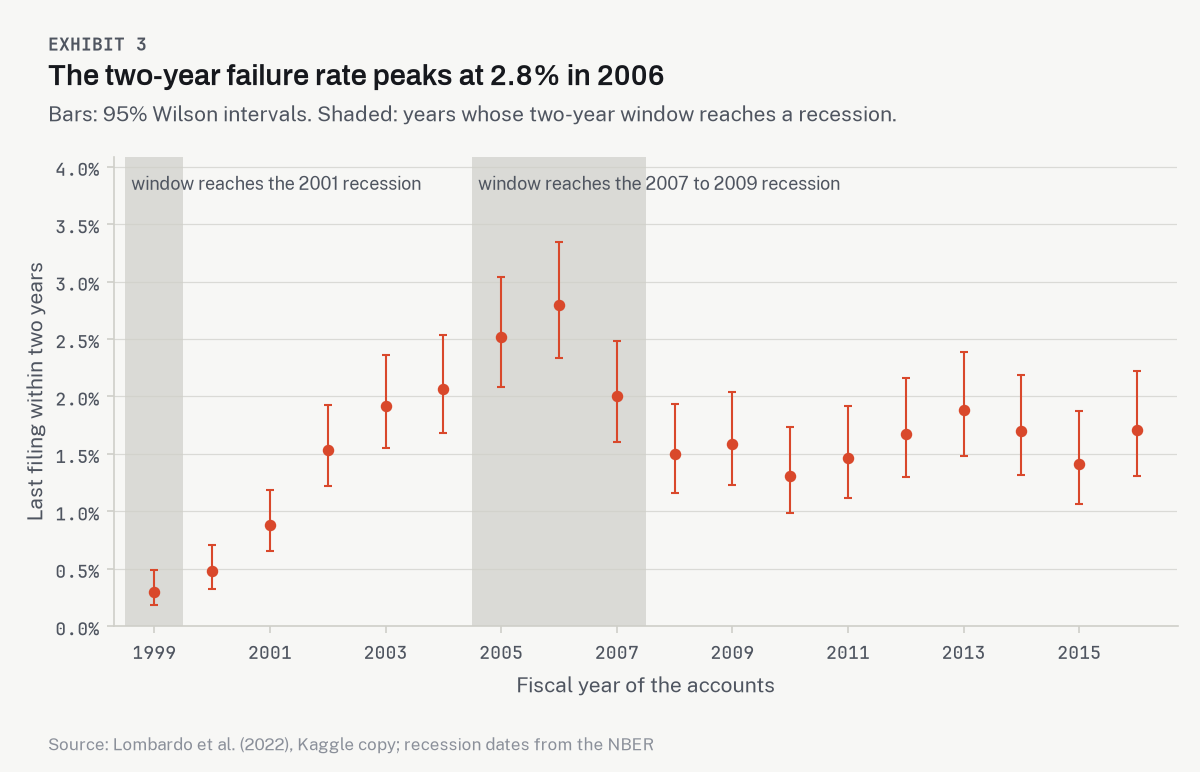

In [14]:
by_year = labelled.groupby("year")["target"].agg(positives="sum", rows="size")
by_year["rate"] = by_year["positives"] / by_year["rows"]
bounds = [wilson_interval(int(k), int(n)) for k, n in zip(by_year["positives"], by_year["rows"])]
by_year = by_year.join(pd.DataFrame(bounds, index=by_year.index, columns=["low", "high"]))

# A filing follows the last fiscal year by one year, so these are the last years
# of the companies that filed for bankruptcy in each recession.
RECESSIONS = {"2001 recession": (2000,), "2007 to 2009 recession": CRISIS_FINAL_YEARS}


def reaching(final_years: tuple[int, ...]) -> list[int]:
    """Labelled years whose window, t + 1 to t + HORIZON, holds one of `final_years`."""
    return [t for t in by_year.index if set(range(t + 1, t + HORIZON + 1)) & set(final_years)]


shaded = {name: reaching(final_years) for name, final_years in RECESSIONS.items()}
assert tuple(shaded["2007 to 2009 recession"]) == CRISIS_FOLDS

peak_year = int(by_year["rate"].idxmax())
store.put("rate_first", by_year.loc[first_year, "rate"])
store.put("positives_first", by_year.loc[first_year, "positives"])
store.put("rate_peak", by_year["rate"].max())
store.put("peak_year", peak_year)

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.8))
top = by_year["high"].max() * 1.22
for name, years in shaded.items():
    ax.axvspan(min(years) - 0.5, max(years) + 0.5, color=viz.RULE, alpha=0.7, linewidth=0)
    ax.text(min(years) - 0.4, top * 0.93, f"window reaches the {name}", size=8.5, color=viz.SLATE)
ax.errorbar(
    by_year.index,
    by_year["rate"],
    yerr=[by_year["rate"] - by_year["low"], by_year["high"] - by_year["rate"]],
    fmt="o",
    color=viz.FAILED,
    markersize=4.5,
    linewidth=1,
    capsize=2,
)
ax.set_xticks(range(first_year, by_year.index.max() + 1, 2))
ax.set_xlim(first_year - 0.7, by_year.index.max() + 0.7)
ax.set_ylim(0, top)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax.grid(axis="x", visible=False)
ax.set_xlabel("Fiscal year of the accounts")
ax.set_ylabel("Last filing within two years")
viz.exhibit(
    fig,
    f"The two-year failure rate peaks at {by_year['rate'].max():.1%} in {peak_year}",
    "Bars: 95% Wilson intervals. Shaded: years whose two-year window reaches a recession.",
    f"{SOURCE}; recession dates from the NBER",
)

**Reading.** In Exhibit 3 the rate climbs from 0.30% in 1999 to 2.80% in 2006.
The years shaded for the 2007 to 2009 recession hold the peak.

The 2001 recession leaves no mark.
Its shaded year has the lowest rate of all, with 16 positive rows.

Failures are thin in the early years: 37 of the 609 failed companies have a last filing of 2002 or earlier.

There are two candidate explanations, and the file cannot choose between them:

- the source may record the early bankruptcies less completely;
- failing companies of those years may have left the file by another door first.

Either way, the early years hold few positives, and a model learns little about failure from them.

**Next, the other door.**

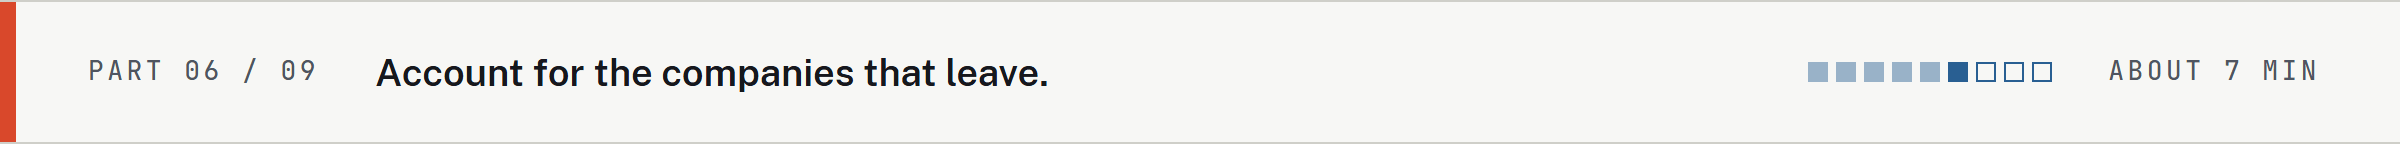

# Everyone Else Who Leaves

The file holds 8,971 companies, and 609 of them fail.
What happens to the rest decides how a zero in the label should be read.

**Predict 2.** Take the companies flagged `alive`.
What share of them are still filing in 2018?

Q. How does the library record the way each history ends?

In [15]:
# taught: corp_default.labels.event_table
def event_table(frame: pd.DataFrame) -> pd.DataFrame:
    """One row per company: entry, exit, duration in years, and how the history ends.

    "failed" is a bankruptcy filing, "reporting" is still filing when the panel ends, and
    "left" is any other exit (acquisition, delisting, going private: the file does not say).
    """
    grouped = frame.groupby("company_name")
    events = grouped["year"].agg(entry_year="min", exit_year="max").reset_index()
    failed = grouped["status_label"].agg(lambda s: bool((s == "failed").any())).to_numpy()
    reporting = events["exit_year"] == PANEL_END
    events["duration"] = events["exit_year"] - events["entry_year"] + 1
    events["event"] = "left"
    events.loc[reporting, "event"] = "reporting"
    events.loc[failed, "event"] = "failed"
    return events

Q. How many companies end each way?

In [16]:
events = event_table(raw)
endings = events["event"].value_counts()
alive = events.loc[events["event"] != "failed", "event"]

store.put("left", endings.loc["left"])
store.put("alive_reporting_share", (alive == "reporting").mean())
store.put("left_per_failed", endings.loc["left"] / endings.loc["failed"])

endings.to_frame("companies").assign(share=(endings / len(events)).round(3))

,companies,share
event,,
left,5675,0.633
reporting,2687,0.300
failed,609,0.068


**Reading.** Only 32% of the companies flagged `alive` are still filing in 2018.
The other 5,675 leave, and the file does not say why.

For every company that fails, 9 leave another way.

Q. How often does each kind of exit happen, year by year?

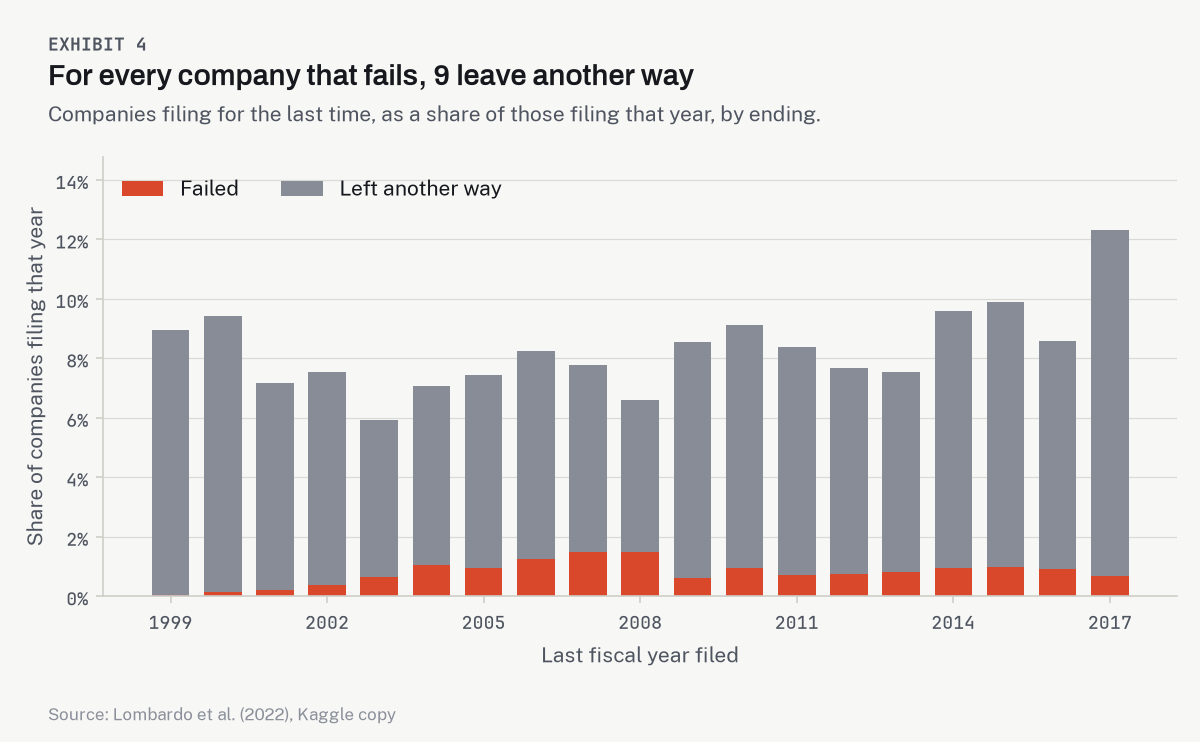

In [17]:
filing = raw.groupby("year")["company_name"].nunique()
exits = (
    events.loc[events["event"] != "reporting"]
    .groupby(["exit_year", "event"])
    .size()
    .unstack(fill_value=0)
)
# No company can be seen to leave in the file's last year, so the chart stops a year short.
exit_rate = exits.div(filing, axis=0).loc[: PANEL_END - 1]
early = exit_rate.loc[:thin_until, "left"]
# The reading below says other exits ran above the typical year early on. Checked here.
assert early.mean() > exit_rate["left"].median()

store.put("left_rate_early", early.mean())
store.put("left_rate_median", exit_rate["left"].median())
store.put("failed_rate_median", exit_rate["failed"].median())

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 3.6))
ax.bar(exit_rate.index, exit_rate["failed"], width=0.72, color=viz.FAILED, label="Failed")
ax.bar(
    exit_rate.index,
    exit_rate["left"],
    bottom=exit_rate["failed"],
    width=0.72,
    color=viz.CENSORED,
    label="Left another way",
)
ax.set_xticks(range(first_year, PANEL_END, 3))
ax.set_ylim(0, exit_rate.sum(axis=1).max() * 1.2)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.grid(axis="x", visible=False)
ax.set_xlabel("Last fiscal year filed")
ax.set_ylabel("Share of companies filing that year")
ax.legend(loc="upper left", ncols=2)
viz.exhibit(
    fig,
    f"For every company that fails, {endings.loc['left'] / endings.loc['failed']:.0f} "
    "leave another way",
    "Companies filing for the last time, as a share of those filing that year, by ending.",
    SOURCE,
)

**Reading.** In Exhibit 4 the red slice is thin in every year.
In a typical year 0.8% of the companies file their last accounts before a bankruptcy, and 7.2% file their last accounts for another reason.

In the thin early years the other exits run at 8.1% a year, a little above the typical year.
That fits the second explanation of the last part, and does not prove it.

The companies that leave could be healthy ones bought by a rival, or weak ones that never reach a bankruptcy court.
The file has no column for it, but the accounts of their last filing can be compared.

The comparison uses fiscal years up to 2011, and sorts the firm-years into three groups.
One group is every row that is not a company's last, and the other two are the last filings of companies that left and of companies that failed.

Q. Do the companies that leave look like the ones that stay?

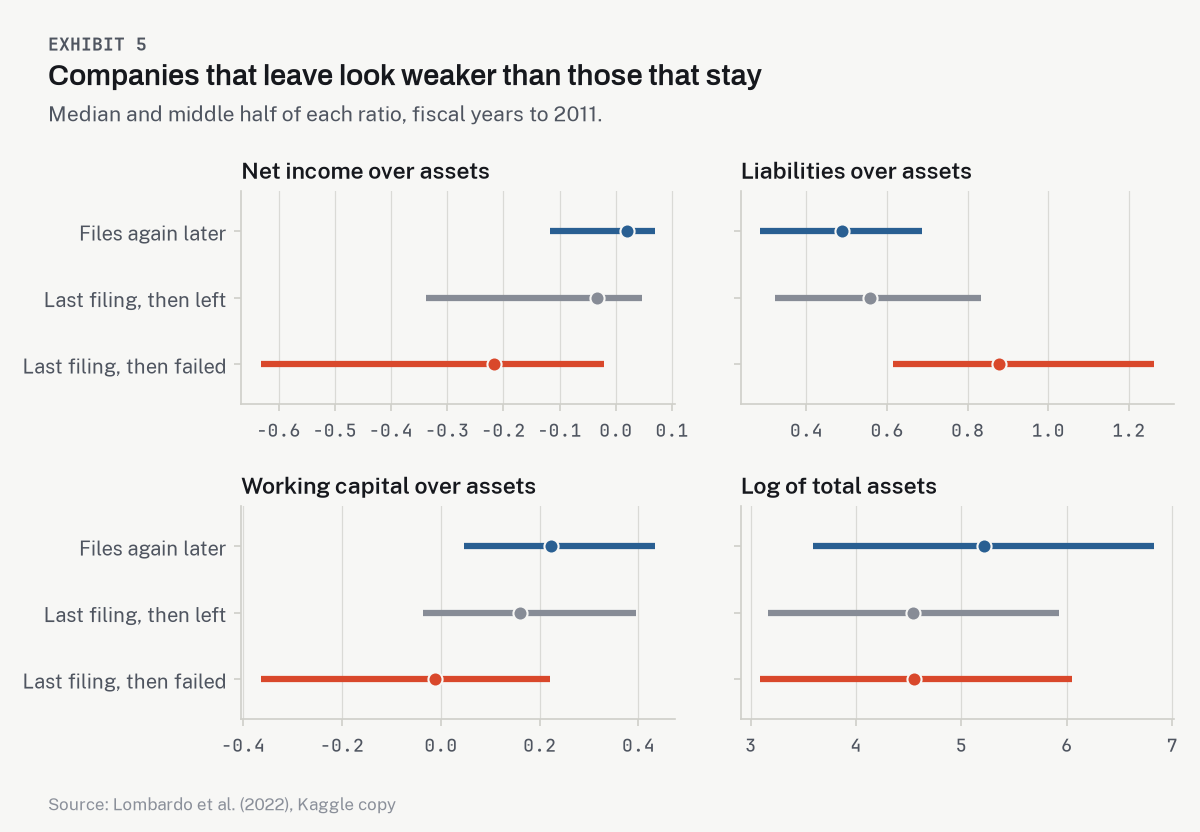

In [18]:
RATIOS = {
    "roa": "Net income over assets",
    "liabilities_to_assets": "Liabilities over assets",
    "working_capital_to_assets": "Working capital over assets",
    "log_assets": "Log of total assets",
}
ending = ratios["company_name"].map(events.set_index("company_name")["event"])
groups = [
    ("Files again later", ratios.loc[to_dev_end & ~is_last], viz.SURVIVED),
    ("Last filing, then left", ratios.loc[to_dev_end & is_last & (ending == "left")], viz.CENSORED),
    ("Last filing, then failed", audit, viz.FAILED),
]
quartiles = pd.concat(
    {name: frame[list(RATIOS)].quantile([0.25, 0.5, 0.75]) for name, frame, _ in groups}
)
medians = quartiles.xs(0.5, level=1)
stay, leave = medians.loc["Files again later"], medians.loc["Last filing, then left"]
# The title says the leavers look weaker on all four ratios. Checked here.
assert leave["roa"] < stay["roa"] and leave["liabilities_to_assets"] > stay["liabilities_to_assets"]
assert leave["working_capital_to_assets"] < stay["working_capital_to_assets"]
assert leave["log_assets"] < stay["log_assets"]

store.put("stay_roa", stay["roa"])
store.put("left_roa", leave["roa"])
store.put("failed_roa", medians.loc["Last filing, then failed", "roa"])

fig, axes = plt.subplots(2, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 4.2), sharey=True)
for ax, (column, title) in zip(axes.flat, RATIOS.items()):
    for place, (name, _, color) in enumerate(groups):
        low, middle, high = quartiles.loc[name, column]
        ax.hlines(place, low, high, color=color, linewidth=3)
        ax.scatter(middle, place, s=46, color=color, edgecolor=viz.SHEET, linewidth=1, zorder=3)
    ax.set_title(title)
    ax.set_yticks(range(len(groups)), [name for name, _, _ in groups])
    ax.set_ylim(len(groups) - 0.4, -0.6)
    ax.grid(axis="y", visible=False)
viz.exhibit(
    fig,
    "Companies that leave look weaker than those that stay",
    f"Median and middle half of each ratio, fiscal years to {DEV_END}.",
    SOURCE,
)

**Reading.** In Exhibit 5 the companies that leave are weaker than those that stay on all four ratios, and smaller.
Their median net income is -3.3% of assets at the last filing, against 2.0% for a firm-year that is followed by another.

They are far from the failed companies too, whose median is -21.6%.

So leaving is not a neutral event.
The label still scores every one of these 5,675 companies as a zero in every year.

**Check.** What does a model learn from a weak company that leaves the file without a bankruptcy?

<details>
<summary>Show the answer</summary>

That weak accounts were followed by no failure.
Each of its rows is a zero, the same as a row of a healthy company that files in every year.

If some of those exits were failures by another name, the model is taught to be too easy on weak companies.
This is a limit of the file, and it stays with every result in the casebook.

</details>

**Next, failure seen from the company's side.**

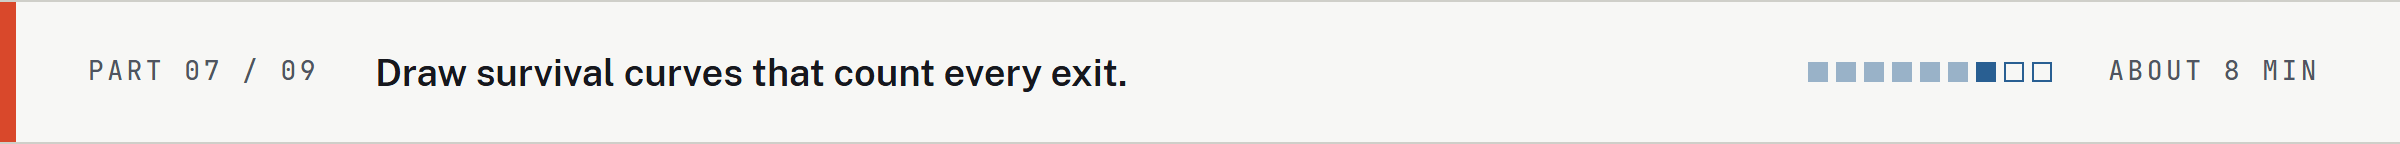

# Survival Curves Done Properly

A **survival curve** asks: of the companies that join, what share have not failed after so many years?
Two choices decide whether it can be trusted: where the clock starts, and what is done with the companies that leave.

The clock here starts at a company's first year in the file.
For a company that joins after 1999, that is the start of its filings as far as the file shows.

The 5,308 companies already there in 1999 are different.
They are a **prevalent cohort**: companies of every age caught at one moment, with their early failures already gone.

So the curves are drawn by the year a company joins.

The **Kaplan-Meier** estimate multiplies, year by year, the share of the companies at risk that do not fail.
A company that leaves, or is still filing when the file ends, is **censored**: it counts as at risk until its last year and then drops out.

Q. How does the library estimate a survival curve?

In [19]:
# taught: corp_default.survival.kaplan_meier
def kaplan_meier(duration, event, entry=None) -> pd.DataFrame:
    """Survival at each distinct duration, with Greenwood standard errors.

    A subject is at risk at time t when entry < t <= duration; entry defaults to 0. Delayed entry
    handles a company first seen part-way through its life: it cannot fail before it is observed.
    """
    duration = np.asarray(duration)
    event = np.asarray(event).astype(bool)
    entry = np.zeros_like(duration) if entry is None else np.asarray(entry)
    if (duration <= entry).any():
        raise ValueError("every duration must be later than its entry")
    times = np.unique(duration)
    at_risk = np.array([((entry < t) & (duration >= t)).sum() for t in times])
    events = np.array([(event & (duration == t)).sum() for t in times])
    survival = np.cumprod(1 - events / at_risk)
    # Greenwood; a step where every subject at risk fails leaves survival at 0 with se 0.
    with np.errstate(divide="ignore", invalid="ignore"):
        terms = np.where(at_risk > events, events / (at_risk * (at_risk - events)), 0.0)
    se = survival * np.sqrt(np.cumsum(terms))
    return pd.DataFrame(
        {"time": times, "at_risk": at_risk, "events": events, "survival": survival, "se": se}
    )

**Reading.** `entry` is for a company first seen partway through its life, when its age at that point is known.
The file gives no ages, so `entry` stays at zero and the prevalent cohort gets a curve of its own.

Q. Does a company's chance of failing depend on when it joined?

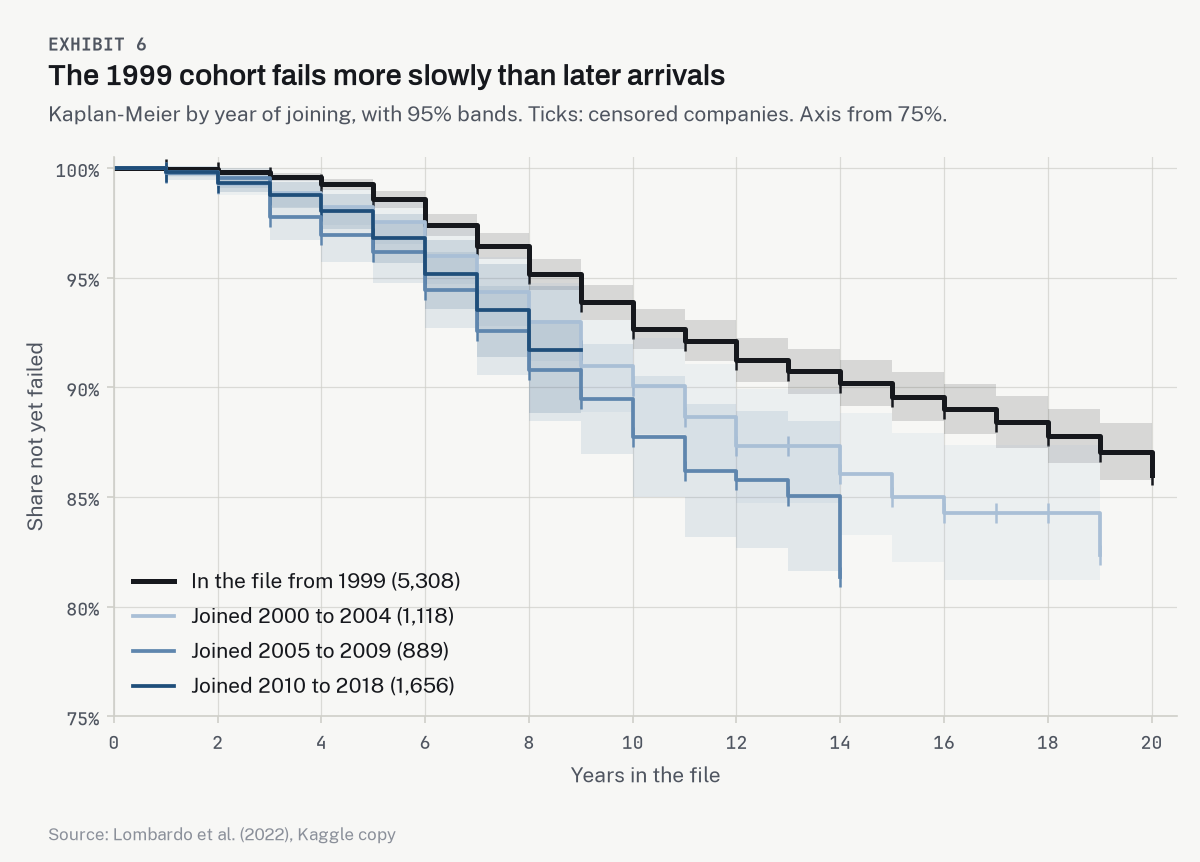

In [20]:
AT = 10  # years in the file at which the curves are compared
cohorts = [
    (f"In the file from {first_year}", events["entry_year"] == first_year, viz.INK),
    ("Joined 2000 to 2004", events["entry_year"].between(2000, 2004), viz.COHORTS[0]),
    ("Joined 2005 to 2009", events["entry_year"].between(2005, 2009), viz.COHORTS[1]),
    (f"Joined 2010 to {last_year}", events["entry_year"] >= 2010, viz.COHORTS[2]),
]


def from_zero(first: float, values) -> np.ndarray:
    """A curve with its starting point, at time zero, put in front."""
    return np.concatenate([[first], values])


fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 4.4))
curves, lowest = {}, 1.0
for label, members, color in cohorts:
    cohort = events.loc[members]
    km = kaplan_meier(cohort["duration"], cohort["event"] == "failed")
    curves[label] = km.set_index("time")["survival"]
    lowest = min(lowest, (km["survival"] - 1.96 * km["se"]).min())
    time = from_zero(0, km["time"])
    ax.step(time, from_zero(1, km["survival"]), where="post", color=color,
            linewidth=2.4 if color == viz.INK else 1.8,
            label=f"{label} ({len(cohort):,})")  # fmt: skip
    ax.fill_between(
        time,
        from_zero(1, km["survival"] - 1.96 * km["se"]),
        from_zero(1, km["survival"] + 1.96 * km["se"]),
        step="post",
        color=color,
        alpha=0.14,
        linewidth=0,
    )
    censored = km.loc[km["time"].isin(cohort.loc[cohort["event"] != "failed", "duration"])]
    ax.scatter(censored["time"], censored["survival"], marker="|", s=90, color=color, linewidth=1.2)

first_label = cohorts[0][0]
# The title says the first cohort fails more slowly. Checked at five years, where every cohort has a value.
assert all(curves[first_label].loc[5] > curves[label].loc[5] for label, _, _ in cohorts[1:])

store.put("at_years", AT)
store.put("cohort_first", int(cohorts[0][1].sum()))
store.put("km_first_at", curves[first_label].loc[AT])
store.put("km_later_at", curves["Joined 2005 to 2009"].loc[AT])

ax.set_xticks(range(0, last_year - first_year + 2, 2))
ax.set_xlim(0, last_year - first_year + 1.5)
floor = np.floor(lowest * 20) / 20  # the nearest five points below the lowest band
ax.set_ylim(floor, 1.005)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlabel("Years in the file")
ax.set_ylabel("Share not yet failed")
ax.legend(loc="lower left")
viz.exhibit(
    fig,
    f"The {first_year} cohort fails more slowly than later arrivals",
    f"Kaplan-Meier by year of joining, with 95% bands. Ticks: censored companies. Axis from {floor:.0%}.",
    SOURCE,
)

**Reading.** In Exhibit 6 the black curve stays on top.
After 10 years the curve of the 1999 cohort stands at 92.7%, against 87.7% for the companies that joined from 2005 to 2009.

Two things differ between the cohorts, and the curves cannot separate them.
The older cohort is made of survivors, and each cohort meets the 2007 to 2009 recession at a different age.

Every curve carries a tick in almost every year, because companies leave in every year.
Kaplan-Meier treats each of those exits as censoring, and that is the second choice.

It answers a question about a world in which no company leaves another way.
It assumes the companies that left would have gone on to fail at the same rate as those that stayed.

**Cumulative incidence** answers the plainer question of what did happen.
Each year it splits the companies going out into failures and other exits, and keeps a running total of each.

**Predict 3.** Of all the companies in the file, what share fail within 10 years of joining?

Q. How does the library count each way out?

In [21]:
# taught: corp_default.survival.cumulative_incidence
def cumulative_incidence(
    duration, cause, causes: tuple[str, ...] = ("failed", "left")
) -> pd.DataFrame:
    """Aalen-Johansen cumulative incidence of each cause; any other value of `cause` is censored.

    survival is the chance of no exit of any listed cause by time t, so survival and the
    incidence columns sum to one at every time.
    """
    duration = np.asarray(duration)
    cause = np.asarray(cause)
    times = np.unique(duration)
    at_risk = np.array([(duration >= t).sum() for t in times])
    by_cause = {
        c: np.array([((duration == t) & (cause == c)).sum() for t in times]) for c in causes
    }
    all_events = sum(by_cause.values())
    survival = np.cumprod(1 - all_events / at_risk)
    before = np.concatenate([[1.0], survival[:-1]])
    table = {"time": times, "at_risk": at_risk, "survival": survival}
    for c in causes:
        table[f"cif_{c}"] = np.cumsum(before * by_cause[c] / at_risk)
    return pd.DataFrame(table)

Q. What share of companies fail, and what share leave another way?

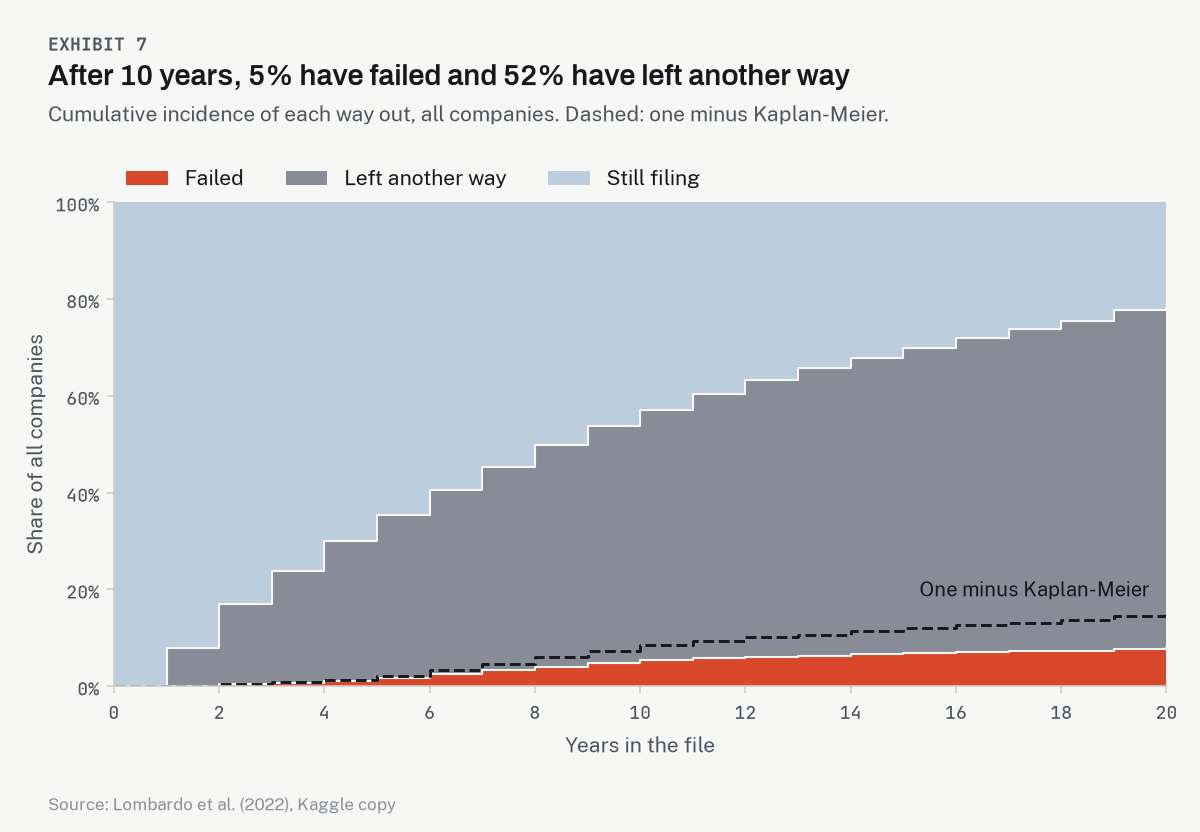

In [22]:
incidence = cumulative_incidence(events["duration"], events["event"]).set_index("time")
km_all = kaplan_meier(events["duration"], events["event"] == "failed").set_index("time")

store.put("km_fail_at", 1 - km_all.loc[AT, "survival"])
store.put("cif_fail_at", incidence.loc[AT, "cif_failed"])
store.put("cif_left_at", incidence.loc[AT, "cif_left"])
store.put("cif_fail_end", incidence["cif_failed"].iloc[-1])
store.put("km_fail_end", 1 - km_all["survival"].iloc[-1])

time = from_zero(0, incidence.index)
failed_share = from_zero(0, incidence["cif_failed"])
gone_share = failed_share + from_zero(0, incidence["cif_left"])

fig, ax = plt.subplots(figsize=(viz.EXHIBIT_WIDTH_IN, 4.2))
ax.fill_between(time, 0, failed_share, step="post", color=viz.FAILED, linewidth=0, label="Failed")
ax.fill_between(time, failed_share, gone_share, step="post", color=viz.CENSORED, linewidth=0,
                label="Left another way")  # fmt: skip
ax.fill_between(time, gone_share, 1, step="post", color="#BCCDDD", linewidth=0,
                label="Still filing")  # fmt: skip
ax.step(time, failed_share, where="post", color=viz.SHEET, linewidth=1)
ax.step(time, gone_share, where="post", color=viz.SHEET, linewidth=1)
ax.step(time, from_zero(0, 1 - km_all["survival"]), where="post", color=viz.INK, linewidth=1.4,
        linestyle="--")  # fmt: skip
ax.annotate("One minus Kaplan-Meier", (time[-1], 1 - km_all["survival"].iloc[-1]), xytext=(-8, 7),
            textcoords="offset points", ha="right", size=9.5)  # fmt: skip
ax.set_xticks(range(0, last_year - first_year + 2, 2))
ax.set_xlim(0, last_year - first_year + 1)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.grid(axis="x", visible=False)
ax.set_xlabel("Years in the file")
ax.set_ylabel("Share of all companies")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1), ncols=3, borderaxespad=0.2)
viz.exhibit(
    fig,
    f"After {AT} years, {incidence.loc[AT, 'cif_failed']:.0%} have failed and "
    f"{incidence.loc[AT, 'cif_left']:.0%} have left another way",
    "Cumulative incidence of each way out, all companies. Dashed: one minus Kaplan-Meier.",
    SOURCE,
    save_as="ch2",
)

**Reading.** In Exhibit 7 the red band is the share of companies that have failed, and after 10 years it stands at 5.4%.
The grey band is far larger: 52% have left another way by then.

The dashed line is one minus Kaplan-Meier, and it reads 8.6% at the same point.
It runs above the red band because it hands every company that left a share of the failures that came later.

By the end of the file the two stand at 15.6% and 7.9%.

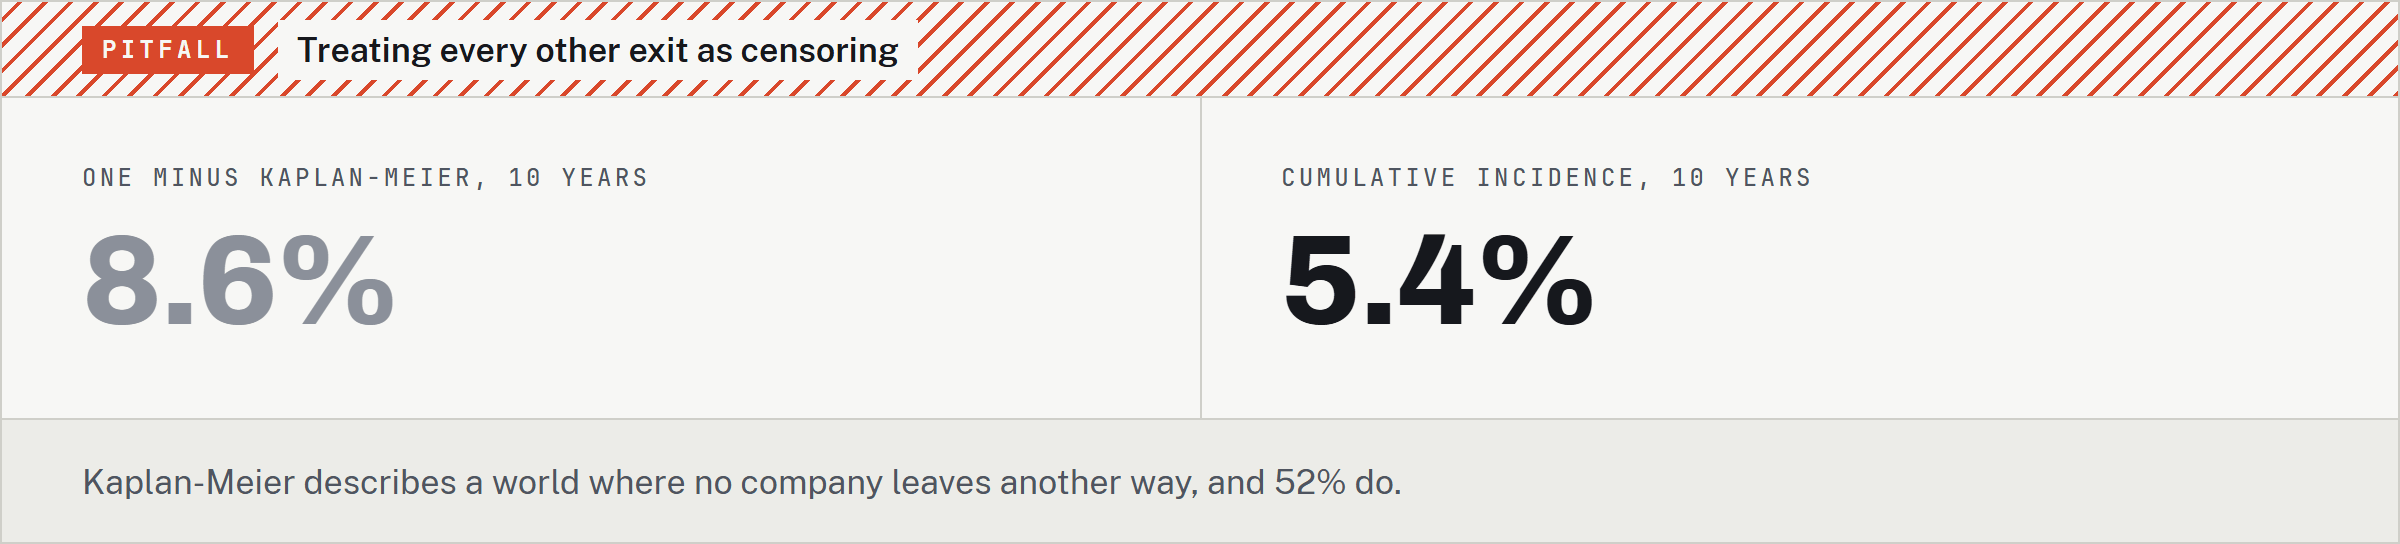

Neither number is wrong, but they answer different questions.
If the question is what share of these companies end in bankruptcy, the answer is the cumulative incidence.

**Next, how far ahead the label should look.**

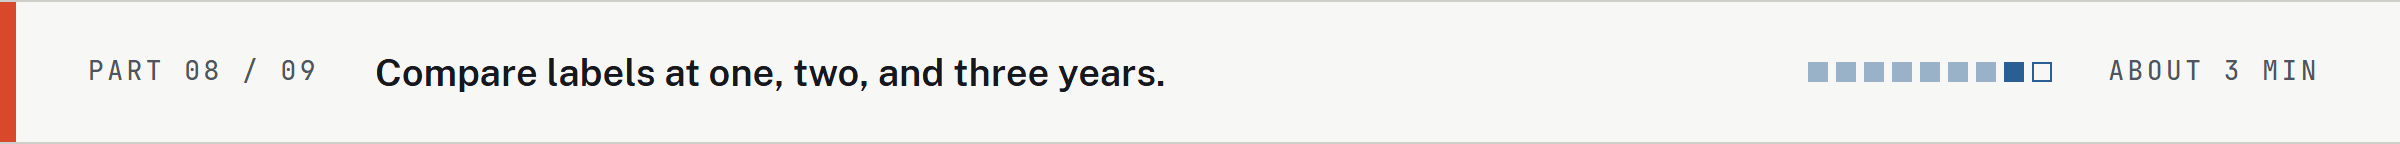

# The Horizon

The label looks two years ahead.
That is a choice, and `build_label` builds the same label at any horizon.

A longer horizon has a second effect, at the end of the file.
A positive row is **unconfirmed** when its company's last row is 2018, the file's last year.

The company is flagged, and that year is the file's last, so no later row can confirm that it stopped.
The paper's table counts these companies as failures of the following year, which supports the label, but the file alone cannot confirm it.

Q. How do the base rate and the unconfirmed share change with the horizon?

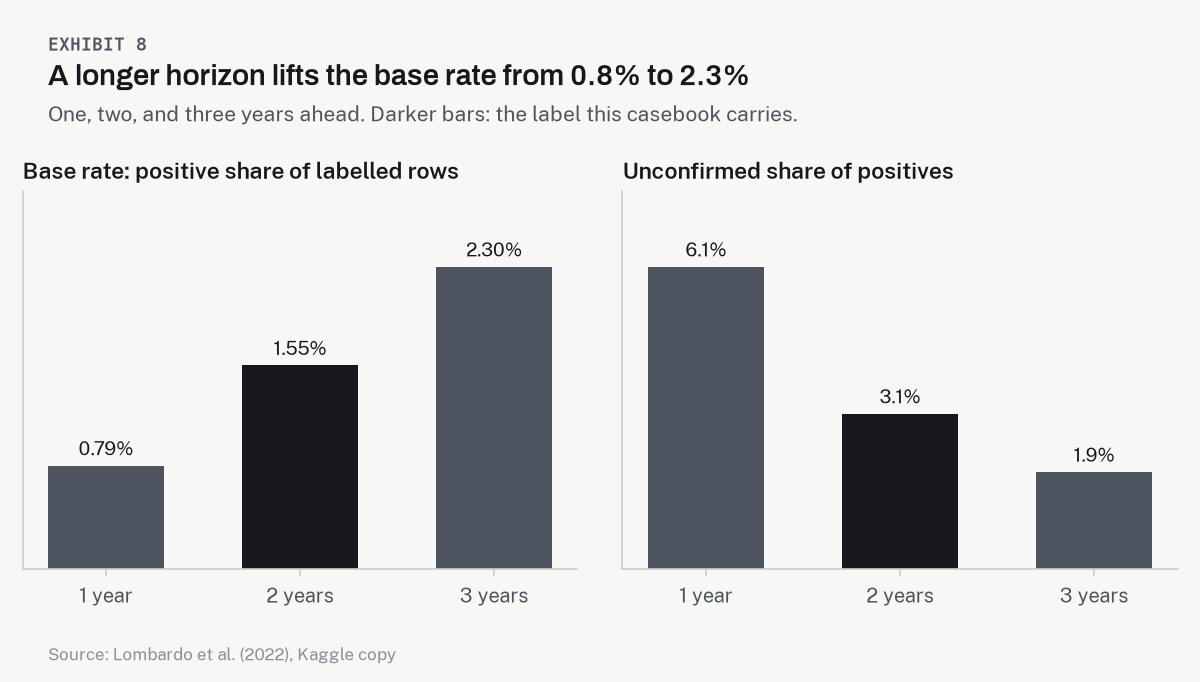

In [23]:
by_horizon = {}
for horizon in (1, 2, 3):
    frame = build_label(raw, horizon)
    hits = frame.loc[frame["target"] == 1]
    by_horizon[horizon] = {
        "rows": len(frame),
        "last year labelled": int(frame["year"].max()),
        "positives": len(hits),
        "base rate": frame["target"].mean(),
        "unconfirmed": int((hits["last_year"] == PANEL_END).sum()),
        "unconfirmed share": (hits["last_year"] == PANEL_END).mean(),
    }
horizons = pd.DataFrame(by_horizon).T
horizons.index.name = "horizon in years"

store.put("positives_1", int(horizons.loc[1, "positives"]))
store.put("positives_3", int(horizons.loc[3, "positives"]))
store.put("base_1", horizons.loc[1, "base rate"])
store.put("base_3", horizons.loc[3, "base rate"])
store.put("unconfirmed_companies", int(final_filings.loc[PANEL_END]))
store.put("unconfirmed_1", horizons.loc[1, "unconfirmed share"])
store.put("unconfirmed_2", horizons.loc[2, "unconfirmed share"])
store.put("unconfirmed_3", horizons.loc[3, "unconfirmed share"])
store.put("rows_lost_3", int(horizons.loc[2, "rows"] - horizons.loc[3, "rows"]))

panels = [
    ("base rate", "Base rate: positive share of labelled rows", 2, 1),
    ("unconfirmed share", "Unconfirmed share of positives", 1, 0),
]
fig, axes = plt.subplots(1, 2, figsize=(viz.EXHIBIT_WIDTH_IN, 3.2))
for ax, (column, title, decimals, axis_decimals) in zip(axes, panels):
    colors = [viz.INK if horizon == HORIZON else viz.SLATE for horizon in horizons.index]
    bars = ax.bar(range(len(horizons)), horizons[column], width=0.6, color=colors)
    ax.bar_label(bars, labels=[f"{value:.{decimals}%}" for value in horizons[column]], padding=3,
                 size=9)  # fmt: skip
    ax.set_title(title)
    ax.set_xticks(range(len(horizons)), ["1 year", "2 years", "3 years"])
    ax.set_ylim(0, horizons[column].max() * 1.25)
    ax.set_yticks([])
    ax.grid(visible=False)
viz.exhibit(
    fig,
    f"A longer horizon lifts the base rate from {horizons.loc[1, 'base rate']:.1%} "
    f"to {horizons.loc[3, 'base rate']:.1%}",
    "One, two, and three years ahead. Darker bars: the label this casebook carries.",
    SOURCE,
)

**Reading.** Exhibit 8 shows the trade.
At one year there are 594 positives, a base rate of 0.79%, and 6.1% of them are unconfirmed.

At three years there are 1,593, and the unconfirmed share falls to 1.9%.
The price is a year of recent data: 3,162 fewer rows than the two-year label keeps.

The same 36 companies sit behind the unconfirmed rows at every horizon.
Their count barely changes, so their share falls as the positives grow.

The casebook carries the two-year label, with 1,123 positives and 3.1% unconfirmed.
It keeps the other two beside it, and Chapter 7 checks the final result against both.

**Next, the tables this chapter hands on.**

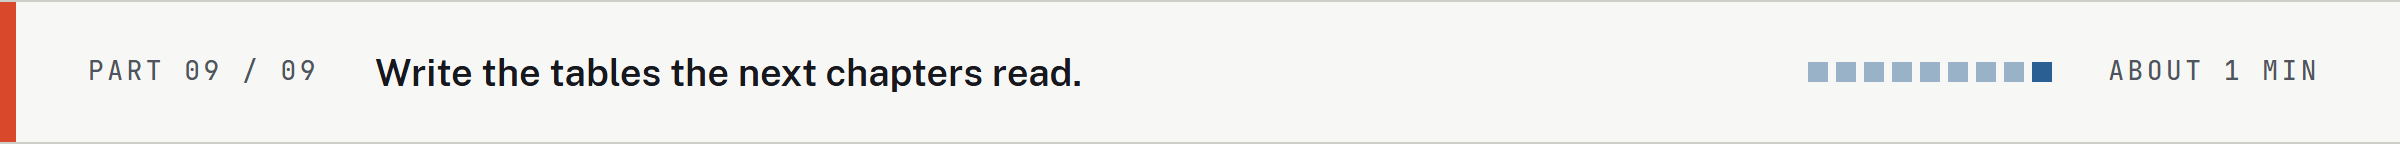

# The Label We Carry Forward

Every later chapter starts from two tables written here.
The **labelled panel** is the file's rows with the label attached, and the event table is the one built above.

Q. What does the labelled panel look like for one failed company?

In [24]:
keys = ["company_name", "year"]
labelled_panel = labelled
for horizon in (1, 3):
    other = build_label(raw, horizon)[[*keys, "target"]]
    other = other.rename(columns={"target": f"target_{horizon}"})
    labelled_panel = labelled_panel.merge(other, on=keys, how="left")

store.save_frame("labelled_panel", labelled_panel)
store.save_frame("event_table", events)
store.put("no_target_3", int(labelled_panel["target_3"].isna().sum()))

# The first failed company with a row in each of the four years before its last.
near_end = labelled_panel.loc[labelled_panel["failed"] & (labelled_panel["last_year"] <= DEV_END)]
near_end = near_end.loc[near_end["years_to_final"] <= 4]
whole = near_end.groupby("company_name")["year"].transform("size") == 4
columns = [*keys, "last_year", "years_to_final", "target_1", "target", "target_3"]
near_end.loc[whole, columns].head(4)

,company_name,year,last_year,years_to_final,target_1,target,target_3
56,C_6,2006,2010,4,0,0,0.0
57,C_6,2007,2010,3,0,0,1.0
58,C_6,2008,2010,2,0,1,1.0
59,C_6,2009,2010,1,1,1,1.0


**Reading.** The three targets switch on one after another as the last filing comes nearer.
The company's last row itself is not in the table.

`target_3` is blank on 3,162 rows, those of 2016, whose three-year window runs past the end of the file.

The labelled panel has 72,393 rows and the event table has 8,971, one for each company.

**The next chapter turns the accounts into ratios and asks where failure shows in them.**

# Findings

1. The flag marks a company and not a year: its share of rows falls from 7.2% to 1.3% only because the future gets shorter (Exhibit 1).
2. A failed company's last filing dates its failure, and at that filing 81% of them report a loss and 75% sit in Altman's distress zone (Exhibit 2).
3. Failure is rare and moves with the cycle: the two-year label has 1,123 positives in 72,393 firm-years, a base rate of 1.55%, and the rate peaks at 2.80% in 2006 (Exhibit 3).
4. A zero in the label means no bankruptcy filed, not a healthy company: for every company that fails, 9 leave another way, and at their last filing they look weaker than the companies that stay (Exhibit 4, Exhibit 5).
5. The companies already in the file in 1999 fail more slowly than later arrivals, as a cohort of survivors would (Exhibit 6).
6. Within 10 years of joining, 5.4% of companies fail, and treating other exits as censoring would say 8.6% (Exhibit 7).
7. A longer horizon lifts the base rate from 0.79% to 2.30% and thins the share of positives that rest on the file's last year (Exhibit 8).

# Your Turn

Three extensions, each with a hint folded under it.

**1. The one-year label by year.** Redraw Exhibit 3 for the one-year label. Does the peak move?

<details>
<summary>Hint</summary>

Start from `build_label(raw, 1)` and repeat the grouping by year.
Inside `reaching`, the window is one year long.

</details>

**2. Survival on the calendar.** Estimate one curve for all companies with the calendar year as the clock, so that a company joining late enters late.

<details>
<summary>Hint</summary>

Use `exit_year - first_year + 1` as the duration and `entry_year - first_year` as `entry` in `kaplan_meier`.

</details>

**3. Cumulative incidence by cohort.** Compare the share that fail within five years for each cohort of Exhibit 6.

<details>
<summary>Hint</summary>

Loop over `cohorts` and call `cumulative_incidence` on `events.loc[members]`.

</details>

[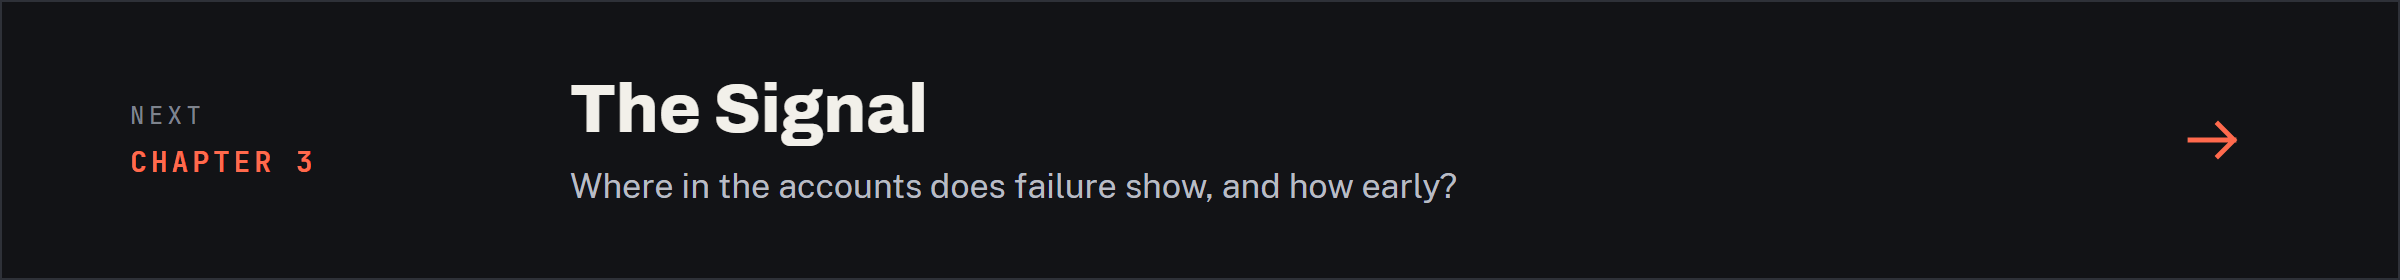](03_the_signal.ipynb)